# Leyenda: Deliverable 3, image captioning

## 1. Context

TouNum digitises paper archives and wants each photograph to come with a short sentence that describes it. This is the last step of the workflow built over the three deliverables:

**load the images -> photo or not? (D1) -> denoising (D2) -> captioning (D3, this notebook)**

The network has two parts: a **CNN** that turns the image into an internal representation, and an **RNN** that writes the caption word by word from this representation. Before training, every image goes once through a CNN **pre-trained for classification** (InceptionV3), and its output is stored on disk.

### What this notebook contains (the four items of the subject)

1. The complete architecture, with the CNN used for the pre-processing: section 3 (explained) and 12.2 (diagram).
2. A short description of the image and text pre-processing: sections 4, 5 and 12.3.
3. The code of the CNN and of the RNN, with explanations: section 6 (and 12.4).
4. The training curves (sections 7 and 12.5) and captioned test images (sections 9 and 12.6).

### Assumptions and choices (stated, not hidden)

- **Data: a subset of MS COCO 2017.** COCO has 118,287 training images with 5 captions each (18 GB). We use 12,000 of them for training, 1,000 other ones for validation, and 1,000 images of the official COCO *val2017* set as our **test set** (drawn with seed 42, see `src/coco.py`). The size is a compromise: some machines of the group have a 2 GB GPU, and the features of one image take 256 KB on disk. More images would give better captions (see section 10).
- **The test set is never used to choose anything**: the vocabulary is built on the training captions only, and early stopping watches the validation set.
- **Images are resized to 299x299 without cropping**, so non-square images are squashed. Cropping would cut out objects that the captions mention.

### How to read this notebook

- **Sections 2 to 10** build and analyse a **first model** (InceptionV3 features, 12,000 COCO images): it shows
  every required element on a small scale (architecture, pre-processing, CNN and RNN code, training curves, test
  examples) and its limits.
- **Section 11** improves it **one change at a time**, each change measured on the same test photos and kept only if
  it is better **on validation**: all of COCO with a 70/15/15 split, a stronger pre-processing CNN (ConvNeXt-Large),
  better decoding, and a reinforcement-learning fine-tuning (SCST).
- **Section 12** presents the **final model** with the required elements again (architecture, pre-processing, code,
  curves, test examples), measured on the **whole 15 % test split** (18,493 photos).
- **Section 13** chains the **whole workflow D1 -> D2 -> D3** on new images; its **last cell** is the one to adapt for
  the evaluation dataset. **Section 14** gives the analysis, the limits and the recommendations for TouNum.

> The workflow of section 13 uses the D1 and D2 of `deliverable1.ipynb` and `deliverable2.ipynb`. `deliverable1_improved.ipynb`, `deliverable2_improved.ipynb` and `deliverable3_improved.ipynb` contain the improvements made with the time left (categories of the rejected images, restoration at full resolution, deblurring).


In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import hashlib
import json
import re
import time
from collections import Counter
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

from src.config import CAPTION_IMG_SIZE, COCO_DIR, SEED
from src.coco import coco_subsets, download_images

keras.utils.set_random_seed(SEED)
tf.get_logger().setLevel("ERROR")   # hides the "tf.function retracing" notices (batches of different sizes)
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    # Memory growth: TensorFlow takes the GPU memory it needs, not everything at once (2 GB cards).
    tf.config.experimental.set_memory_growth(gpus[0], True)
print("GPU:", [g.name for g in gpus] or "none (the feature extraction and the training would be slow on CPU)")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

GPU: ['/physical_device:GPU:0']
TensorFlow 2.21.0 | Keras 3.15.1 | numpy 2.5.3 | pandas 3.0.6 | matplotlib 3.11.2


E0000 00:00:1792660033.516990  697435 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792660035.186156  697435 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792660035.186417  697435 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.


## 2. The data: MS COCO captions

`coco_subsets()` reads the official caption files of COCO 2017 and draws the three sets with a fixed seed: train and validation come from COCO *train2017* and never share an image, the test set comes from COCO *val2017*, a separate set of images. `download_images()` fetches only these 14,000 images from the COCO server (about 2.3 GB, once; the images already on disk are skipped). Everything goes to `data/coco/`, which is not versioned.

In [2]:
t0 = time.time()
train_images, val_images, test_images = coco_subsets()
images = {"train": train_images, "val": val_images, "test": test_images}
paths = {name: download_images(ims) for name, ims in images.items()}

ids = {name: {im["id"] for im in ims} for name, ims in images.items()}
assert not ids["train"] & ids["val"], "an image is in train and in validation"
for name, ims in images.items():
    n_captions = sum(len(im["captions"]) for im in ims)
    print(f"{name:5s}: {len(ims):6,} images | {n_captions:6,} captions | from COCO {ims[0]['split']}")
print(f"Ready in {time.time() - t0:.0f} s")

train: 12,000 images | 60,037 captions | from COCO train2017
val  :  1,000 images |  5,003 captions | from COCO train2017
test :  1,000 images |  5,002 captions | from COCO val2017
Ready in 5 s


### What one example looks like

Each image has at least 5 captions written by different people. They do not describe the same things, and they do not use the same words: there is no single right answer. We keep this in mind for the evaluation (section 8).

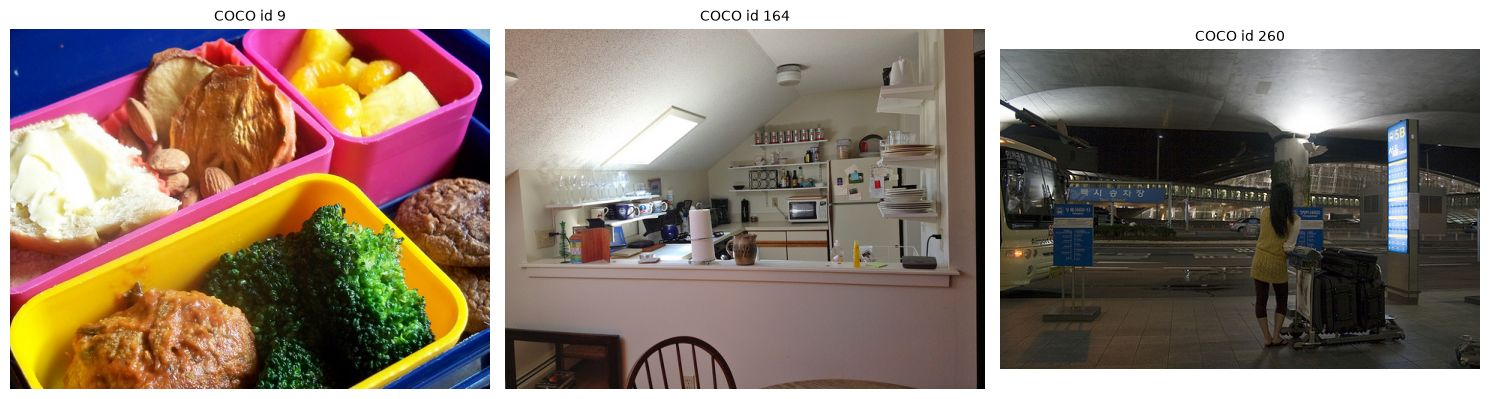

COCO id 9:
   - Closeup of bins of food that include broccoli and bread.
   - A meal is presented in brightly colored plastic trays.
   - there are containers filled with different kinds of foods
   - Colorful dishes holding meat, vegetables, fruit, and bread.
   - A bunch of trays that have different food.
COCO id 164:
   - A small kitchen with low a ceiling
   - A small kichen area with a sunlight and and angled ceiling.
   - an image of a kitchen loft style setting
   - a small kitchen with a lot of filled up shelves
   - A kitchen with a slanted ceiling and skylight.
COCO id 260:
   - A female traveler leaning on a luggage cart.
   - A woman is waiting with a cart full of luggage.
   - A woman next to a cart of luggage at a bus stop.
   - the woman is standing with her luggage
   - A woman wearing a yellow shirt standing next to luggage.


In [3]:
from PIL import Image

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, im, path in zip(axes, train_images[:3], paths["train"][:3]):
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(f"COCO id {im['id']}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()
for im in train_images[:3]:
    print(f"COCO id {im['id']}:")
    for c in im["captions"]:
        print("   -", c)

## 3. Architecture of the captioning network

The complete network is drawn in section 12.2 (the final model: same layers, ConvNeXt-Large instead of InceptionV3). The pre-processing CNN runs **once**, before any training; the rest is the model we train.

### 3.1 The CNN used for the pre-processing: InceptionV3

- **What it is.** InceptionV3 (Szegedy et al., 2015) is a convolutional network trained to classify the 1.28 million images of ImageNet into 1,000 classes. Its *Inception blocks* run convolutions of several sizes (1x1, 3x3, 5x5 factorised into smaller ones, pooling) in parallel and stack their outputs, so one block sees small and large patterns at the same time. It has 48 layers and 21.8 million parameters without its classification head.
- **What we take from it.** We remove the classification head (`include_top=False`) and keep the output of the last convolutional block (`mixed10`): for a 299x299 image it is an **8x8 grid of 2,048 numbers**. Each of the 64 cells describes one region of the image (about 37x37 pixels of the input, with a much larger field of view) with high-level features learned on ImageNet: textures, object parts, objects.
- **Why a pre-trained CNN (transfer learning).** 12,000 images are far too few to learn to see from scratch; ImageNet already taught InceptionV3 to recognise objects. Its weights are **frozen**: we only use it, we do not train it.
- **Why keep the grid and not one vector.** The pooled 2,048 vector (one per image) would lose *where* things are. With 64 regions the decoder can look at a different region for each word (attention, section 6).
- **Why compute it once and store it.** The 14,000 images go through InceptionV3 once (a few minutes), and the training then reads 64x2,048 numbers per image from disk instead of running 23 million parameters at every epoch. This only works because InceptionV3 is frozen.

### 3.2 The model we train: CNN encoder + RNN decoder with attention

- **CNN encoder.** One dense layer applied to each of the 64 regions (2,048 -> 512, ReLU). It adapts the generic ImageNet features to the captioning task. It is the trainable "CNN part": the convolutions themselves are in InceptionV3.
- **Initial state.** The mean of the 64 encoded regions goes through a dense layer (tanh) and becomes the first hidden state of the GRU: the decoder starts with a summary of the whole image.
- **RNN decoder.** The previous word goes through an **embedding** (index -> vector of 256 numbers, learned), then a **GRU** with 512 units. The GRU keeps a memory (hidden state) of the words already written; its gates decide, at each step, what to keep and what to update.
- **Attention.** At each step the GRU state is compared with the 64 regions (scaled dot product), a softmax turns the scores into 64 weights that sum to 1, and the **context** is the weighted mean of the regions: what the decoder looks at to write the next word.
- **Output.** GRU state and context are concatenated, normalised (layer normalization), mixed by a dense layer (tanh), and a last dense layer gives one score per word of the vocabulary (5,000). The softmax turns them into the probability of each word being the next one.

## 4. Image pre-processing

Three steps for each image, in a `tf.data` pipeline that reads the images batch by batch (the 14,000 images are never all in memory):

1. **Read** the JPEG and force 3 colour channels (some COCO images are greyscale).
2. **Resize to 299x299**, the input size InceptionV3 was trained with (antialiasing on, to avoid artefacts when shrinking large photos).
3. **Scale the pixels from [0, 255] to [-1, 1]**: this is the scaling used when InceptionV3 was trained on ImageNet (`keras.applications.inception_v3.preprocess_input` does exactly `x / 127.5 - 1`). With another scaling the pre-trained filters would receive values they never saw.

Then InceptionV3 gives the 8x8x2048 grid, reshaped into 64 regions x 2048, and written to a `.npy` file per set. The features are stored as **float16** (half the size of float32: 3.1 GB instead of 6.3 GB for the training set); the cell checks that this rounding is negligible. The file is read with `mmap_mode="r"`: only the rows of the current batch are loaded in memory.

In [5]:
N_REGIONS, FEATURE_DIM = 64, 2048
FEATURES_DIR = Path(COCO_DIR) / "features"
FEATURES_DIR.mkdir(parents=True, exist_ok=True)


def read_for_inception(path):
    # Read one image -> 299x299x3 float32 in [-1, 1], the input InceptionV3 expects.
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, [CAPTION_IMG_SIZE, CAPTION_IMG_SIZE], antialias=True)   # float32 in [0, 255]
    img.set_shape([CAPTION_IMG_SIZE, CAPTION_IMG_SIZE, 3])
    return img / 127.5 - 1.0   # = keras.applications.inception_v3.preprocess_input


inception = keras.applications.InceptionV3(include_top=False, weights="imagenet",
                                           input_shape=(CAPTION_IMG_SIZE, CAPTION_IMG_SIZE, 3))
inception.trainable = False
print(f"InceptionV3 without its head: {inception.count_params():,} parameters (frozen), output {inception.output_shape}")


@tf.function   # compiled once: much faster and lighter on GPU memory than running the layers one by one
def inception_features(batch):
    # Batch of pre-processed images -> (batch, 64, 2048) float32.
    return tf.reshape(inception(batch, training=False), (-1, N_REGIONS, FEATURE_DIM))


def extract_features(name, image_paths, batch_size=16):   # 16: fits a 2 GB GPU
    # Features of every image of a set, computed once and cached on disk (read with memory mapping).
    # The file name contains a hash of the list of paths: another subset never reuses a wrong file.
    key = hashlib.md5("|".join(image_paths).encode()).hexdigest()[:10]
    out = FEATURES_DIR / f"inceptionv3_{name}_{len(image_paths)}_{key}.npy"
    done = out.with_suffix(".done")   # written last: an interrupted extraction is started again
    if not done.exists():
        t0 = time.time()
        feats = np.lib.format.open_memmap(out, mode="w+", dtype=np.float16,
                                          shape=(len(image_paths), N_REGIONS, FEATURE_DIM))
        ds = (tf.data.Dataset.from_tensor_slices(image_paths)
              .map(read_for_inception, num_parallel_calls=tf.data.AUTOTUNE)
              .batch(batch_size).prefetch(tf.data.AUTOTUNE))
        i = 0
        for batch in ds:
            f = inception_features(batch).numpy()
            feats[i:i + len(f)] = f.astype(np.float16)
            i += len(f)
        feats.flush()
        del feats
        done.touch()
        print(f"{name}: features of {len(image_paths):,} images computed in {time.time() - t0:.0f} s")
    return np.load(out, mmap_mode="r")


features = {name: extract_features(name, p) for name, p in paths.items()}
for name, f in features.items():
    print(f"{name:5s}: {f.shape} {f.dtype} | {f.nbytes / 1e9:.2f} GB on disk")

# float16 check: the same images in float32, compared with what is stored.
check = inception_features(tf.stack([read_for_inception(p) for p in paths["val"][:16]])).numpy()
stored = features["val"][:16].astype(np.float32)
print(f"float16 rounding: max abs error {np.abs(check - stored).max():.4f} | "
      f"relative error of the norm {np.linalg.norm(check - stored) / np.linalg.norm(check):.1e} | "
      f"features in [{check.min():.1f}, {check.max():.1f}], {100 * (check == 0).mean():.0f} % zeros (ReLU)")

E0000 00:00:1792655560.406472  691495 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792655560.406812  691495 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792655560.407057  691495 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792655560.737927  691495 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792655560.738778  691495 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792655560.739012  691495 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.


InceptionV3 without its head: 21,802,784 parameters (frozen), output (None, 8, 8, 2048)
train: (12000, 64, 2048) float16 | 3.15 GB on disk
val  : (1000, 64, 2048) float16 | 0.26 GB on disk
test : (1000, 64, 2048) float16 | 0.26 GB on disk
float16 rounding: max abs error 0.0075 | relative error of the norm 2.1e-04 | features in [0.0, 25.8], 61 % zeros (ReLU)


## 5. Text pre-processing

The network works on numbers, so each caption becomes a list of word indexes:

1. **Cleaning.** Lower case, and keep only the words made of letters (punctuation and digits are dropped; "t-shirt" becomes "t shirt").
2. **Start and end markers.** `<start>` is added in front (the first input of the decoder: it has to start from something) and `<end>` at the end (the network learns to stop by predicting it).
3. **Vocabulary: the most frequent words.** We count the words of the **training** captions only and keep the 4,996 most frequent ones, plus 4 special tokens (`<pad>`, `<unk>`, `<start>`, `<end>`): 5,000 words. Rare words (a few occurrences each) cannot be learned anyway; they become `<unk>` (unknown).
4. **Word indexes.** Each word gets its rank in the vocabulary (`<pad>` = 0, `<unk>` = 1, `<start>` = 2, `<end>` = 3, then 4 = the most frequent word, ...).
5. **Padding.** All the sequences get the same length (`MAX_LEN` = 22: `<start>`, up to 20 words, `<end>`), completed with `<pad>` = 0, so that they fit in one tensor. The few captions longer than 20 words are not used for training (they stay as references in the evaluation).
6. **Input and target, shifted by one.** For training, the input of the decoder is the sequence without its last token and the target is the sequence without its first one: at each position the network must predict the **next** word. Giving the true previous word (not the predicted one) during training is called *teacher forcing*.

In [6]:
PAD, UNK, START, END = "<pad>", "<unk>", "<start>", "<end>"
VOCAB_SIZE = 5000
MAX_WORDS = 20
MAX_LEN = MAX_WORDS + 2   # <start> + words + <end>


def clean(caption):
    # Lower case, words made of letters only.
    return re.findall(r"[a-z]+", caption.lower())


word_counts = Counter(w for im in train_images for c in im["captions"] for w in clean(c))
# Sorted by count, then alphabetically: the same vocabulary on every machine (ties are frequent).
by_frequency = sorted(word_counts, key=lambda w: (-word_counts[w], w))
vocab = [PAD, UNK, START, END] + by_frequency[:VOCAB_SIZE - 4]
word_index = {w: i for i, w in enumerate(vocab)}

covered = sum(word_counts[w] for w in vocab[4:])
print(f"Distinct words in the training captions: {len(word_counts):,}; kept: {len(vocab) - 4:,} "
      f"(+4 special tokens) = {len(vocab):,}")
print(f"They cover {100 * covered / sum(word_counts.values()):.2f} % of the word occurrences; the least frequent "
      f"kept word ('{vocab[-1]}') appears {word_counts[vocab[-1]]} times")
print("Most frequent words:", ", ".join(vocab[4:24]))


def encode(words):
    # Word list -> MAX_LEN indexes: <start>, words (unknown -> <unk>), <end>, then <pad> = 0.
    ids = [word_index[START]] + [word_index.get(w, word_index[UNK]) for w in words] + [word_index[END]]
    return ids + [word_index[PAD]] * (MAX_LEN - len(ids))


def make_pairs(ims):
    # One (image number, encoded caption) pair per caption of at most MAX_WORDS words.
    img_idx, seqs = [], []
    for i, im in enumerate(ims):
        for c in im["captions"]:
            words = clean(c)
            if 0 < len(words) <= MAX_WORDS:
                img_idx.append(i)
                seqs.append(encode(words))
    return np.array(img_idx, np.int32), np.array(seqs, np.int32)


pairs = {name: make_pairs(images[name]) for name in ("train", "val")}
for name, (img_idx, seqs) in pairs.items():
    n_all = sum(len(im["captions"]) for im in images[name])
    print(f"{name:5s}: {len(seqs):,} (image, caption) pairs, {n_all - len(seqs)} captions longer than "
          f"{MAX_WORDS} words left out ({100 * (n_all - len(seqs)) / n_all:.1f} %) | tensor {seqs.shape}")

Distinct words in the training captions: 10,312; kept: 4,996 (+4 special tokens) = 5,000
They cover 98.95 % of the word occurrences; the least frequent kept word ('aimed') appears 2 times
Most frequent words: a, on, of, the, in, with, and, is, man, to, sitting, an, two, at, people, are, standing, next, white, woman
train: 59,657 (image, caption) pairs, 380 captions longer than 20 words left out (0.6 %) | tensor (59657, 22)
val  : 4,982 (image, caption) pairs, 21 captions longer than 20 words left out (0.4 %) | tensor (4982, 22)


### The training pipeline

`tf.data` yields batches of 64 `((image features, input words), target words)`. Only the **pairs** (image number, caption) are shuffled; the features of the batch are read from the memory-mapped file and converted to float32 at that moment. With 5 captions per image, one epoch sees each training image about 5 times, once with each caption.

In [8]:
BATCH = 64


def make_caption_dataset(feats, img_idx, seqs, training=False):
    ds = tf.data.Dataset.from_tensor_slices((img_idx, seqs))
    if training:
        ds = ds.shuffle(len(seqs), seed=SEED, reshuffle_each_iteration=True)   # new order at every epoch
    ds = ds.batch(BATCH)

    def load(idx, seq):
        # Read the features of the batch from disk (float16 -> float32).
        f = tf.numpy_function(lambda i: feats[i].astype(np.float32), [idx], tf.float32)
        f.set_shape([None, N_REGIONS, FEATURE_DIM])
        # Teacher forcing: input = sequence without its last token, target = sequence without its first.
        return (f, seq[:, :-1]), seq[:, 1:]

    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)


train_ds = make_caption_dataset(features["train"], *pairs["train"], training=True)
val_ds = make_caption_dataset(features["val"], *pairs["val"])
(f, words_in), words_out = next(iter(val_ds))
print("one batch: features", f.shape, f.dtype, "| input words", words_in.shape, "| target words", words_out.shape)
print(f"{len(pairs['train'][1]) // BATCH + 1} batches (iterations) per epoch")

one batch: features (64, 64, 2048) <dtype: 'float32'> | input words (64, 21) | target words (64, 21)
933 batches (iterations) per epoch


## 6. The code of the CNN and of the RNN

`build_captioner()` builds the network of section 3.2 with the Keras functional API. It returns two models that **share the same layers and weights**: `captioner` (outputs the word scores, used for training) and `captioner_attention` (also outputs the attention weights, used to draw them in section 9).

**Shapes**, for a batch of B images and captions of T = 21 positions: features (B, 64, 2048) -> encoded regions (B, 64, 512); words (B, 21) -> embeddings (B, 21, 256) -> GRU states (B, 21, 512) -> context (B, 21, 512) -> scores (B, 21, 5000).

The GRU processes the 21 positions in order, but during training all of them are computed in one call, because the true previous words are known (teacher forcing). The attention is computed for each position from the GRU state of that position only, so the prediction at position t never sees the words after t.

**Loss: masked cross-entropy.** For each position, the cross-entropy between the 5,000 scores and the true next word (softmax included, `from_logits=True`). The `<pad>` positions are not real words, so they are **masked**: the loss is the mean over the real words only. Without the mask, a large part of the loss would be "predict `<pad>` after `<end>`", which is trivial. The **masked accuracy** is the share of real words where the most likely word is the true one. **Optimizer:** Adam, learning rate 1e-3, with **gradient clipping** (`clipnorm=1.0`). **Dropout** 0.3 after the encoder and before the output, against overfitting.

**Two safeguards, added after a failed first run.** Our first training on the 12,000 images stalled in the first epoch: the loss stayed at 5.5 and the model wrote "a" for every word (14 % accuracy, the share of "a" among the words). The same code learned normally on 2,000 images, so the data was right and the training had become unstable. The concatenated vector mixes the GRU state (between -1 and 1) with the attention context (built from InceptionV3 features up to about 24). We measured it on the saved weights of that run: its values were 44 on average and up to 613, so **100 % of the outputs of the next `tanh` were stuck at -1 or +1**, in the flat part where the gradient is almost zero: the network could not learn any more. **Layer normalization** rescales this vector before the `tanh`, and **gradient clipping** limits the size of one update, a classic protection for RNNs. With both, the same training reaches a validation accuracy of 44 % after 2 epochs.

In [9]:
EMBED_DIM, UNITS, ATT_DIM, DROPOUT = 256, 512, 256, 0.3


def masked_loss(y_true, y_pred):
    # Cross-entropy on the real words only (<pad> = 0 is ignored).
    loss = keras.losses.sparse_categorical_crossentropy(y_true, y_pred, from_logits=True)
    mask = tf.cast(tf.not_equal(y_true, 0), loss.dtype)
    return tf.reduce_sum(loss * mask) / tf.reduce_sum(mask)


def masked_accuracy(y_true, y_pred):
    # Share of the real words where the most likely word is the right one.
    y_true = tf.cast(y_true, tf.int64)
    mask = tf.cast(tf.not_equal(y_true, 0), tf.float32)
    hit = tf.cast(tf.equal(tf.argmax(y_pred, axis=-1), y_true), tf.float32)
    return tf.reduce_sum(hit * mask) / tf.reduce_sum(mask)


def build_captioner():
    # CNN encoder + GRU decoder with attention. Returns (training model, same model + attention weights).
    keras.utils.set_random_seed(SEED)   # same initial weights at every run
    features_in = keras.Input((N_REGIONS, FEATURE_DIM), name="image_features")
    words_in = keras.Input((MAX_LEN - 1,), dtype="int32", name="previous_words")

    # TimeDistributed(Dense): the SAME dense layer applied to each region (or each word position) separately.
    # (A plain Dense on a 3-D tensor gives the same result but its gradient needs 64x more GPU memory.)

    # ---- CNN part (encoder): the same dense layer on each of the 64 regions, 2048 -> 512.
    regions = keras.layers.TimeDistributed(keras.layers.Dense(UNITS, activation="relu"), name="encoder_dense")(features_in)
    regions = keras.layers.Dropout(DROPOUT, name="encoder_dropout")(regions)

    # ---- First GRU state: a summary of the whole image (mean of the regions).
    summary = keras.layers.GlobalAveragePooling1D(name="mean_of_regions")(regions)
    h0 = keras.layers.Dense(UNITS, activation="tanh", name="initial_state")(summary)

    # ---- RNN part (decoder).
    x = keras.layers.Embedding(VOCAB_SIZE, EMBED_DIM, name="embedding")(words_in)   # index -> vector of 256
    h = keras.layers.GRU(UNITS, return_sequences=True, name="gru")(x, initial_state=h0)  # one state per position

    # ---- Attention: each GRU state (query) looks at the 64 regions (keys and values).
    # One head = scaled dot product: softmax(q . k / sqrt(ATT_DIM)) over the regions, after learned projections.
    attention = keras.layers.MultiHeadAttention(num_heads=1, key_dim=ATT_DIM, name="attention")
    context, scores = attention(query=h, value=regions, key=regions, return_attention_scores=True)

    # ---- Output: one score per word of the vocabulary (the softmax is in the loss).
    x = keras.layers.Concatenate(name="state_and_context")([h, context])
    # LayerNormalization: brings each vector back to mean 0 / std 1 (then a learned scale and shift).
    # Without it the context, built from large ImageNet features, saturates the tanh below and training stalls.
    x = keras.layers.LayerNormalization(name="normalise")(x)
    x = keras.layers.TimeDistributed(keras.layers.Dense(UNITS, activation="tanh"), name="combine")(x)
    x = keras.layers.Dropout(DROPOUT, name="output_dropout")(x)
    logits = keras.layers.TimeDistributed(keras.layers.Dense(VOCAB_SIZE), name="next_word_scores")(x)

    model = keras.Model([features_in, words_in], logits, name="captioner")
    # clipnorm=1.0: if the gradient is very large (it happens with RNNs), it is scaled down to a norm of 1.
    model.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0), loss=masked_loss, metrics=[masked_accuracy])
    with_attention = keras.Model([features_in, words_in], [logits, scores], name="captioner_attention")
    return model, with_attention


captioner, captioner_attention = build_captioner()
captioner.summary()

Model: "captioner"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_features      │ (None, 64, 2048)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dense       │ (None, 64, 512)   │  1,049,088 │ image_features[0… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dropout     │ (None, 64, 512)   │          0 │ encoder_dense[0]… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ previous_words      │ (None, 21)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mean_of_regions     │ (None, 512)       │          0 │ encoder_dropout[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 21, 256)   │  1,280,000 │ previous_words[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ initial_state       │ (None, 512)       │    262,656 │ mean_of_regions[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 21, 512)   │  1,182,720 │ embedding[0][0],  │
│                     │                   │            │ initial_state[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, 21, 512), │    525,568 │ encoder_dropout[… │
│ (MultiHeadAttentio… │ (None, 1, 21,     │            │ gru[0][0],        │
│                     │ 21)]              │            │ encoder_dropout[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ state_and_context   │ (None, 21, 1024)  │          0 │ gru[0][0],        │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalise           │ (None, 21, 1024)  │      2,048 │ state_and_contex… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combine             │ (None, 21, 512)   │    524,800 │ normalise[0][0]   │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_dropout      │ (None, 21, 512)   │          0 │ combine[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_word_scores    │ (None, 21, 5000)  │  2,565,000 │ output_dropout[0… │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,391,880 (28.20 MB)

 Trainable params: 7,391,880 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

## 7. Training

### Settings

- **Data:** the training pairs (image, caption), shuffled at every epoch, batches of 64. One **epoch** is one pass over all the pairs; one **iteration** is one batch, i.e. one update of the weights.
- **Loss / metric:** masked cross-entropy / masked accuracy (section 6). **Optimizer:** Adam, learning rate 1e-3.
- **Early stopping:** we stop when the validation loss has not improved for `PATIENCE` = 3 epochs and keep the best weights (`MAX_EPOCHS` is only an upper bound). The validation captions are never used for anything else.
- **Saved weights:** written to `models/d3_captioner_<date>.weights.h5` as soon as the validation loss improves, with the history and the vocabulary next to them. If they exist, the notebook reloads them instead of training again (`RETRAIN = True` to train again). The vocabulary is checked on reload: weights trained with another vocabulary would give nonsense.

In [11]:
MODELS = Path("models")
MODELS.mkdir(exist_ok=True)
MAX_EPOCHS, PATIENCE = 30, 3
RETRAIN = False   # True: ignore the saved weights and train again


def train_or_load(name, model):
    # Train `model` (or reload its latest saved weights) and return its history.
    saved = sorted(MODELS.glob(f"d3_{name}_[0-9]*.weights.h5"))   # the timestamp sorts alphabetically
    if saved and not RETRAIN:
        weights = saved[-1]
        saved_vocab = json.loads(weights.with_name(weights.name.replace(".weights.h5", "_vocab.json")).read_text())
        assert saved_vocab == vocab, "these weights were trained with another vocabulary: set RETRAIN = True"
        model.load_weights(weights)
        history = json.loads(weights.with_name(weights.name.replace(".weights.h5", "_history.json")).read_text())
        print(f"Reloaded {weights.name} ({len(history['loss'])} epochs, trained in "
              f"{history['seconds'] / 60:.0f} min), no training.")
        return history

    weights = MODELS / f"d3_{name}_{datetime.now():%Y%m%d_%H%M%S}.weights.h5"
    weights.with_name(weights.name.replace(".weights.h5", "_vocab.json")).write_text(json.dumps(vocab))
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(weights, monitor="val_loss", save_best_only=True, save_weights_only=True),
    ]
    t0 = time.time()
    fit = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS, callbacks=callbacks, verbose=2)
    history = {k: [float(v) for v in vals] for k, vals in fit.history.items()}
    history["seconds"] = time.time() - t0
    weights.with_name(weights.name.replace(".weights.h5", "_history.json")).write_text(json.dumps(history))
    print(f"Trained {len(history['loss'])} epochs in {history['seconds'] / 60:.0f} min, best weights in {weights.name}")
    return history


history = train_or_load("captioner", captioner)

Reloaded d3_captioner_20261021_091720.weights.h5 (7 epochs, trained in 8 min), no training.


/home/utilisateur/Bureau/Layanda/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 46 variables. 
  saveable.load_own_variables(store)


### Training curves

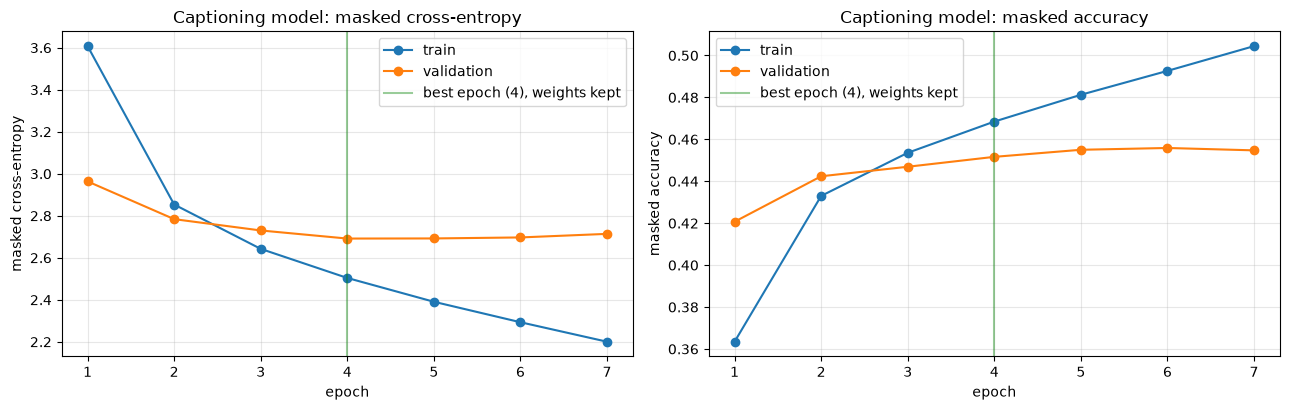

Best epoch 4: train loss 2.504 | val loss 2.692 (perplexity 14.8) | train accuracy 0.468 | val accuracy 0.452


In [12]:
epochs = np.arange(1, len(history["loss"]) + 1)
best = int(np.argmin(history["val_loss"]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, metric, label in [(axes[0], "loss", "masked cross-entropy"), (axes[1], "masked_accuracy", "masked accuracy")]:
    ax.plot(epochs, history[metric], marker="o", label="train")
    ax.plot(epochs, history[f"val_{metric}"], marker="o", label="validation")
    ax.axvline(best + 1, color="green", alpha=0.4, label=f"best epoch ({best + 1}), weights kept")
    ax.set_xlabel("epoch"); ax.set_ylabel(label); ax.set_title(f"Captioning model: {label}")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()
print(f"Best epoch {best + 1}: train loss {history['loss'][best]:.3f} | val loss {history['val_loss'][best]:.3f} "
      f"(perplexity {np.exp(history['val_loss'][best]):.1f}) | train accuracy {history['masked_accuracy'][best]:.3f} | "
      f"val accuracy {history['val_masked_accuracy'][best]:.3f}")

**Reading (numbers of our run, seed 42).**

- **Best epoch: 4.** The validation loss goes from 2.95 to 2.68 (perplexity 14.6: on average the model hesitates as if it had to choose between about 15 words), then rises again while the training loss keeps falling (2.48 at epoch 4, 2.17 at epoch 7). From epoch 5 the model learns the training captions by heart instead of things that generalise: this is **overfitting**, and early stopping kept the weights of epoch 4. Training took 7 epochs, 7 minutes.
- **Train above validation at the start** (epochs 1 and 2): normal, the training loss is the mean over an epoch during which the weights improve, and dropout is only active during training.
- **Accuracy 45.8 %** on validation: almost one next word in two is exactly the human one. It looks low, but many words have equivalents ("man" / "person", "sitting" / "standing" in some images) that this measure counts as wrong. The captions themselves are judged in section 8.
- **Why it overfits so early.** 7.4 million parameters against 12,000 images: the model has enough capacity to memorise their 60,000 captions. More images is the most direct fix (section 10).

## 8. Writing captions and measuring them

### 8.1 Generation (greedy decoding)

After training there is no true previous word any more. We start from `<start>`, take the **most likely** word, give it back as the next input, and repeat until `<end>` (or 21 words). `<pad>`, `<unk>` and `<start>` are never chosen. All the test images are processed together, batch by batch. Because the GRU only looks backwards, running the model on the sequence written so far gives exactly the prediction of the next position.

### 8.2 BLEU, and two references to read it

**BLEU** (Papineni et al., 2002) is the usual score for generated sentences: it counts how many groups of *n* consecutive words (n-grams) of the generated caption appear in the human captions of the same image (counts clipped, so that repeating a correct word is not rewarded), for n = 1 to 4, and takes their geometric mean. A **brevity penalty** lowers the score of captions shorter than the references. BLEU-1 measures the choice of words, BLEU-4 also the word order. It is computed on the whole test set (corpus BLEU), with our own 25-line implementation below. It follows the original definition and gives the same numbers as `nltk.translate.bleu_score.corpus_bleu` (checked on random corpora), except for captions shorter than *n* words, which NLTK counts as one n-gram.

A BLEU score alone means little, so we compare with two references, all computed on the **same test images and against the same human captions**:

- **Human:** one of the human captions (the first one) scored against the others. It shows how much two people agree: a model cannot be expected to do much better.
- **Nearest training image (retrieval):** no RNN at all. We find the training image whose InceptionV3 features are the most similar (cosine of the mean of the 64 regions) and copy its first caption. If the model does not beat this, the RNN learned nothing more than "similar images, similar captions".

To keep the three rows comparable, the first human caption of each test image is kept aside and every method is scored against the **remaining ones** (4 or more per image).

In [13]:
BANNED = [word_index[PAD], word_index[UNK], word_index[START]]


def generate(feats, batch_size=125):
    # Greedy decoding for a (n, 64, 2048) array of features. Returns the captions (word lists) and the index sequences.
    captions, sequences = [], []
    for s in range(0, len(feats), batch_size):
        f = np.asarray(feats[s:s + batch_size], dtype=np.float32)
        n = len(f)
        seq = np.zeros((n, MAX_LEN - 1), np.int32)
        seq[:, 0] = word_index[START]
        out = np.zeros((n, MAX_LEN - 1), np.int32)
        finished = np.zeros(n, bool)
        for t in range(MAX_LEN - 1):
            scores = captioner.predict_on_batch([f, seq])[:, t]   # (n, VOCAB_SIZE) for position t
            scores[:, BANNED] = -np.inf
            nxt = scores.argmax(axis=-1)
            out[:, t] = np.where(finished, word_index[PAD], nxt)
            finished |= nxt == word_index[END]
            if finished.all():
                break
            if t + 1 < MAX_LEN - 1:
                seq[:, t + 1] = nxt
        for row in out:
            words = []
            for i in row:
                if i in (word_index[END], word_index[PAD]):
                    break
                words.append(vocab[i])
            captions.append(words)
        sequences.append(seq)
    return captions, np.concatenate(sequences)


def corpus_bleu(references, hypotheses, max_n=4):
    # references: one list of word lists per image; hypotheses: one word list per image. Returns BLEU-1..max_n.
    clipped, total = np.zeros(max_n), np.zeros(max_n)
    hyp_len = ref_len = 0
    for refs, hyp in zip(references, hypotheses):
        hyp_len += len(hyp)
        # Reference length for the brevity penalty: the closest one (the shorter one in case of a tie).
        ref_len += min((abs(len(r) - len(hyp)), len(r)) for r in refs)[1]
        for n in range(1, max_n + 1):
            grams = Counter(tuple(hyp[i:i + n]) for i in range(len(hyp) - n + 1))
            max_in_ref = Counter()
            for r in refs:
                for g, c in Counter(tuple(r[i:i + n]) for i in range(len(r) - n + 1)).items():
                    max_in_ref[g] = max(max_in_ref[g], c)
            clipped[n - 1] += sum(min(c, max_in_ref[g]) for g, c in grams.items())
            total[n - 1] += max(len(hyp) - n + 1, 0)
    brevity = 1.0 if hyp_len > ref_len else np.exp(1 - ref_len / max(hyp_len, 1))
    with np.errstate(divide="ignore"):
        log_p = np.log(clipped / np.maximum(total, 1))
    return {f"BLEU-{n}": float(brevity * np.exp(log_p[:n].mean())) for n in range(1, max_n + 1)}


t0 = time.time()
test_captions, test_sequences = generate(features["test"])
print(f"{len(test_captions)} test captions generated in {time.time() - t0:.0f} s")

1000 test captions generated in 41 s


In [14]:
def mean_region_features(feats, chunk=500):
    # Mean of the 64 regions of each image, L2-normalised (for the cosine similarity).
    m = np.concatenate([feats[s:s + chunk].astype(np.float32).mean(axis=1) for s in range(0, len(feats), chunk)])
    return m / np.linalg.norm(m, axis=1, keepdims=True)


train_mean, test_mean = mean_region_features(features["train"]), mean_region_features(features["test"])
nearest = (test_mean @ train_mean.T).argmax(axis=1)   # most similar training image, for each test image
retrieval_captions = [clean(train_images[j]["captions"][0]) for j in nearest]

held_out = [clean(im["captions"][0]) for im in test_images]           # the "human" row
references = [[clean(c) for c in im["captions"][1:]] for im in test_images]
train_caption_set = {" ".join(clean(c)) for im in train_images for c in im["captions"]}

rows = {}
for name, hyps in [("Human (one caption vs the others)", held_out),
                   ("Nearest training image (retrieval)", retrieval_captions),
                   ("Our model (CNN + GRU + attention)", test_captions)]:
    row = corpus_bleu(references, hyps)
    row["mean length (words)"] = np.mean([len(h) for h in hyps])
    row["distinct captions"] = len({" ".join(h) for h in hyps})
    row["copied from training (%)"] = 100 * np.mean([" ".join(h) in train_caption_set for h in hyps])
    rows[name] = row
results = pd.DataFrame(rows).T
print(f"Test set: {len(test_images)} COCO val2017 images, scored against {sum(map(len, references)):,} human captions")
results.style.format({**{f"BLEU-{n}": "{:.3f}" for n in range(1, 5)}, "mean length (words)": "{:.1f}",
                      "distinct captions": "{:.0f}", "copied from training (%)": "{:.1f}"})

Test set: 1000 COCO val2017 images, scored against 4,002 human captions


,BLEU-1,BLEU-2,BLEU-3,BLEU-4,mean length (words),distinct captions,copied from training (%)
Human (one caption vs the others),0.641,0.445,0.301,0.204,10.4,998,3.5
Nearest training image (retrieval),0.459,0.266,0.158,0.097,10.5,900,100.0
Our model (CNN + GRU + attention),0.607,0.412,0.265,0.170,9.8,765,11.9


**Reading (numbers of our run).**

- **The model is far above the retrieval baseline**: BLEU-4 0.179 against 0.097 (+85 %), BLEU-1 0.617 against 0.459. The RNN does more than "similar image, similar caption": it composes captions adapted to each image (only 9.9 % of its captions are copies of a training caption).
- **It is close to the human row** (BLEU-4 0.179 against 0.204, BLEU-1 0.617 against 0.641). This does **not** mean that its captions are as good as human ones. BLEU rewards the most usual wording: a person who writes something specific ("two very sexy women in bikinis", section 9) is penalised because the others did not say it, while the model learned to say the most likely thing. The last columns show it: the model writes shorter captions (9.5 words against 10.4) and is less varied (750 different captions for 1,000 images, against 998).
- **For comparison only:** published models trained on the whole of COCO (118,000 images) report BLEU-4 around 0.25 to 0.30 against 5 references. Our numbers are not directly comparable (12,000 images, 4 references, our own split), but the order of magnitude is consistent.

## 9. Test examples

### 9.1 Captioned test images

Eight test images drawn at random (seed 42, not chosen by hand), with the caption of the model and one human caption.

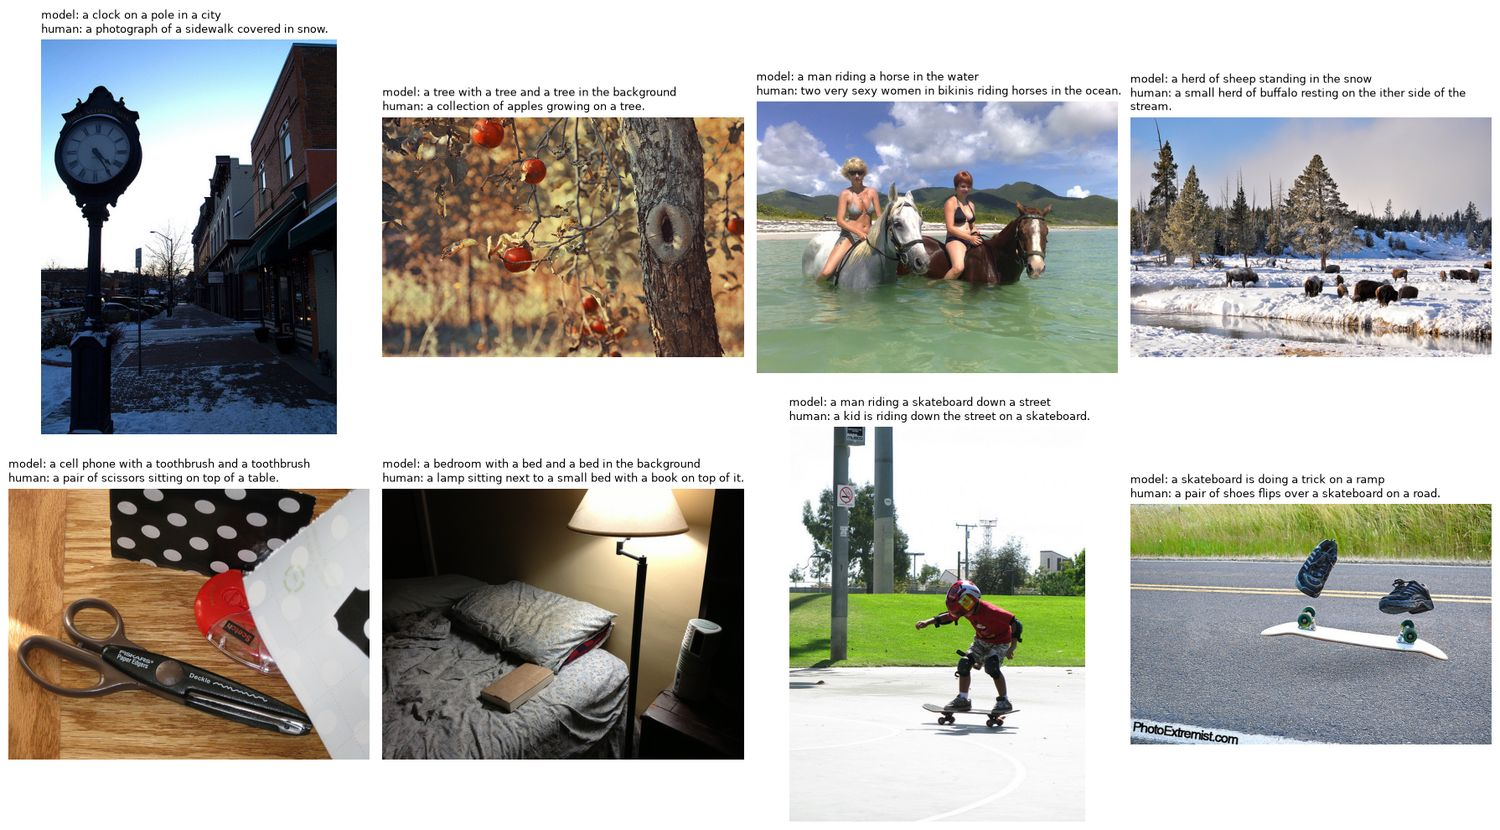

In [15]:
rng = np.random.default_rng(SEED)
shown = sorted(rng.choice(len(test_images), 8, replace=False))
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
for ax, i in zip(axes.ravel(), shown):
    ax.imshow(Image.open(paths["test"][i]).convert("RGB"))
    ax.set_title(f"model: {' '.join(test_captions[i])}\nhuman: {test_images[i]['captions'][0].strip().lower()}",
                 fontsize=9.5, loc="left", wrap=True)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Reading.** The main object or the scene is right in 6 of the 8 images (clock and building, tree with fruit, horse in the water, scissors, bedroom with a bed and a lamp, skateboard in the street). The errors are typical of this kind of model:

- **The most frequent training situations win.** The buffalo in the snow become "a group of people are riding on the snow" (snow in COCO is mostly skiing), and the flying shoes become "a person riding a skateboard on a ramp", the usual skateboard sentence.
- **Details are guessed from statistics:** "a man" for two women and for a child, "oranges" for red apples, an invented "remote control" next to the scissors.
- **Repetitions** ("a clock ... with a clock on it", "a tree ... in a tree"): greedy decoding chooses each word alone and has no way to correct the sentence afterwards (beam search, section 10, reduces this).

## 10. Analysis of this first model (12,000 images)

- **What works.** Grammatical captions that name the main object or scene in most test images (6 of the 8 examples of
  section 9). BLEU-4 0.179 on the 1,000 test images: twice the retrieval baseline (0.097), close to the agreement
  between two humans (0.204).
- **The limit: variance.** Overfitting from epoch 5 (section 7): 7.4 million parameters for 12,000 images. The errors of
  section 9 (people instead of buffalo, "a man" for everybody) are the same problem: few examples of rare situations,
  so the model falls back on the frequent ones.
- **A training failure, and what it taught.** The first training stalled at "always write *a*": the output `tanh` was
  saturated by the large ImageNet features (100 % of its outputs at -1 or +1). Layer normalisation and gradient
  clipping fixed it. A curve that does not move from the first epoch is a bug or an instability, not a lack of epochs.
- **What to change, by expected gain:** (1) more images, all of COCO; (2) a more recent pre-processing CNN; (3) beam
  search instead of greedy decoding (repetitions, an early mistake can never be corrected). Section 11 makes these
  changes one at a time, and adds a reinforcement-learning step (SCST).


## 11. Improving the captioner, one change at a time

Section 10 showed the main limit of the first model: **overfitting from epoch 5**, because 12,000 images are not
enough. The improvements below follow the same rules as in deliverables 1 and 2:

1. **One change at a time**, so that the effect of each change is known.
2. **Every choice on the validation set**; the test photos are only used to report.
3. **The same test photos for every model**: 5,000 photos of our test split that the first model never saw (it was
   trained on part of COCO *train2017*, which is now spread over our three splits), scored against their 4 other
   human captions with the same BLEU as in section 8. Section 12 then measures the final model on the **whole**
   test split.

| Step | Change | BLEU-4 (5,000 test photos) |
|---|---|---|
| Section 7 | first model: InceptionV3, 12,000 images | 0.180 |
| 11.1 | **all of COCO** (86,301 training images, 70/15/15 split) | 0.216 |
| 11.2 | pre-processing CNN **EfficientNetV2-S** | 0.229 |
| 11.2 | pre-processing CNN **ConvNeXt-Large**, then the training continued | 0.253 -> 0.264 |
| 11.3 | **beam search** (3) without repeated word pairs | 0.289 |
| 11.4 | **SCST** (reinforcement learning on the CIDEr-D score) | see 11.4 |
| | *a human caption scored against the 4 others* | *0.190* |

### 11.1 All of MS COCO, split 70 / 15 / 15

**Why.** The first model saw 12,000 images and overfitted after 4 epochs. COCO 2017 has 123,287 captioned images
(*train2017* + *val2017*). We use **all of them**, split at random (seed 42) into **70 % training, 15 % validation,
15 % test**, the same proportions as in deliverables 1 and 2. The vocabulary is built on the training captions only.

**Same model, same settings** as sections 6 and 7; two practical changes, which do not change what the model learns:

- **Features computed in mixed precision** (16-bit on the GPU), 3 times faster; they are stored in 16-bit anyway.
- **One caption per image and per epoch**, drawn at random among its 5: the 22 GB of training features do not fit in
  the 15 GB of RAM and are read from disk; reading each image once per epoch instead of 5 times divides the reading
  by 5, and over 5 epochs the model sees as many captions. Validation uses a fixed caption per image, so that its
  curve is comparable from one epoch to the next.

In [17]:
import gc
import hashlib

from src.coco import image_path, load_captions

nour_seen = {im["id"] for im in train_images + val_images}       # images used to train / validate the first model
pool = load_captions("train2017") + load_captions("val2017")     # all the captioned images of COCO 2017
order = np.random.default_rng(SEED).permutation(len(pool))
n_tr, n_va = int(round(0.70 * len(pool))), int(round(0.15 * len(pool)))
split = {"train": sorted((pool[i] for i in order[:n_tr]), key=lambda im: im["id"]),
         "val": sorted((pool[i] for i in order[n_tr:n_tr + n_va]), key=lambda im: im["id"]),
         "test": sorted((pool[i] for i in order[n_tr + n_va:]), key=lambda im: im["id"])}
ids_ = {k: {im["id"] for im in v} for k, v in split.items()}
assert not (ids_["train"] & ids_["val"] or ids_["train"] & ids_["test"] or ids_["val"] & ids_["test"])
for k, v in split.items():
    print(f"{k:5s}: {len(v):7,} images ({100 * len(v) / len(pool):.1f} %), {sum(len(im['captions']) for im in v):,} captions")
paths_all = {k: [image_path(im) for im in v] for k, v in split.items()}   # all of COCO is on disk (unzipped once)

# The 5,000 test photos used to compare the models of this section (never seen by the first model either).
fair = [i for i, im in enumerate(split["test"]) if im["id"] not in nour_seen][:5000]
fair_set = set(fair)
refs_fair = [[clean(c) for c in split["test"][i]["captions"][1:]] for i in fair]
print(f"comparison set: {len(fair):,} test photos, each scored against 4 human captions")

train:  86,301 images (70.0 %), 431,730 captions
val  :  18,493 images (15.0 %), 92,521 captions
test :  18,493 images (15.0 %), 92,516 captions
comparison set: 5,000 test photos, each scored against 4 human captions


In [18]:
def extract_all(name, image_paths, build_encoder, read, n_regions, dim, batch_size):
    # Features of every image, computed once with a frozen pre-trained CNN and cached on disk (16-bit). The CNN is only
    # built if a file is missing, and freed afterwards (a large CNN and the captioner do not fit together in 2 GB).
    key = hashlib.md5("|".join(image_paths).encode()).hexdigest()[:10]
    out = FEATURES_DIR / f"inceptionv3_{name}_{len(image_paths)}_{key}.npy"   # same naming as section 4
    done = out.with_suffix(".done")
    if not done.exists():
        t0 = time.time()
        keras.mixed_precision.set_global_policy("mixed_float16")   # 16-bit computations on the GPU: about 3x faster
        encoder = build_encoder()
        encoder.trainable = False
        keras.mixed_precision.set_global_policy("float32")
        feats = np.lib.format.open_memmap(out, mode="w+", dtype=np.float16, shape=(len(image_paths), n_regions, dim))
        ds = tf.data.Dataset.from_tensor_slices(image_paths).map(read, num_parallel_calls=tf.data.AUTOTUNE)
        i = 0
        for batch in ds.batch(batch_size).prefetch(tf.data.AUTOTUNE):
            f = np.asarray(encoder.predict_on_batch(batch), np.float32).reshape(-1, n_regions, dim)
            feats[i:i + len(f)] = f.astype(np.float16)
            i += len(f)
        feats.flush()
        del feats, encoder
        gc.collect()
        done.touch()
        print(f"{name}: features of {len(image_paths):,} images computed in {time.time() - t0:.0f} s")
    return np.load(out, mmap_mode="r")


inception_v3 = lambda: keras.applications.InceptionV3(include_top=False, weights="imagenet",
                                                      input_shape=(CAPTION_IMG_SIZE, CAPTION_IMG_SIZE, 3))
feats_incv3 = {k: extract_all(f"{k}_all", paths_all[k], inception_v3, read_for_inception, 64, 2048, 32) for k in split}
for k, f in feats_incv3.items():
    print(f"InceptionV3 features, {k:5s}: {f.shape} {f.dtype} | {f.nbytes / 1e9:.1f} GB on disk")

# The first model (section 7, still in memory with its vocabulary) on the comparison photos, before the vocabulary changes.
f_fair_incv3 = lambda: feats_incv3["test"][np.array(fair)]   # 5,000 x 64 x 2048, read from disk when needed
comparison, comparison_caps = {}, {}


def compare(name, caps):
    comparison_caps[name] = caps
    row = corpus_bleu(refs_fair, caps)
    row["distinct captions"] = len({" ".join(c) for c in caps})
    row["mean length"] = np.mean([len(c) for c in caps])
    comparison[name] = row
    return row


CAPTION_CACHE = FEATURES_DIR / "captions"
CAPTION_CACHE.mkdir(exist_ok=True)
caption_seconds = {}


def cached_captions(key, make):
    # Writing captions takes time (beam search: 25 min for the test split): they are written once and saved with
    # the time they took; the key contains the weights file and the decoding settings, so a new model never
    # reuses old captions.
    f = CAPTION_CACHE / f"{key}.json"
    if f.exists() and not RETRAIN:
        saved = json.loads(f.read_text())
    else:
        t0 = time.time()
        saved = {"captions": make(), "seconds": None}
        saved["seconds"] = time.time() - t0
        f.write_text(json.dumps(saved))
    caption_seconds[key] = saved["seconds"]
    return saved["captions"]


compare("Human (one caption vs the 4 others)", [clean(split["test"][i]["captions"][0]) for i in fair])
first_w = sorted(MODELS.glob("d3_captioner_[0-9]*.weights.h5"))[-1].name
compare("Section 7: first model (12,000 images)", cached_captions(f"fair_{first_w}", lambda: generate(f_fair_incv3())[0]))

InceptionV3 features, train: (86301, 64, 2048) float16 | 22.6 GB on disk
InceptionV3 features, val  : (18493, 64, 2048) float16 | 4.8 GB on disk
InceptionV3 features, test : (18493, 64, 2048) float16 | 4.8 GB on disk


In [19]:
# Vocabulary of the new training captions (same rules as section 5), then the per-image datasets.
word_counts = Counter(w for im in split["train"] for c in im["captions"] for w in clean(c))
by_frequency = sorted(word_counts, key=lambda w: (-word_counts[w], w))
vocab = [PAD, UNK, START, END] + by_frequency[:VOCAB_SIZE - 4]
word_index = {w: i for i, w in enumerate(vocab)}
BANNED = [word_index[PAD], word_index[UNK], word_index[START]]
covered = sum(word_counts[w] for w in vocab[4:])
print(f"{len(word_counts):,} distinct words in the training captions; the {VOCAB_SIZE - 4:,} kept cover "
      f"{100 * covered / sum(word_counts.values()):.2f} % of the occurrences")
caps_by_img = {k: [np.array([encode(clean(c)) for c in im["captions"] if 0 < len(clean(c)) <= MAX_WORDS], np.int32)
                   for im in split[k]] for k in ("train", "val")}


def make_image_dataset(feats, caps, training):
    # Batches of (features, caption without its last word) -> caption without its first word (teacher forcing).
    rng_np = np.random.default_rng(SEED)
    ds = tf.data.Dataset.from_tensor_slices(np.arange(len(caps)))
    if training:
        ds = ds.shuffle(len(caps), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH)

    def read(i):
        i = np.sort(i)   # sorted reads from the memory-mapped file
        if training:     # one caption at random per image, a new draw at every epoch
            s = np.stack([caps[j][rng_np.integers(len(caps[j]))] for j in i])
        else:            # validation: a fixed caption per image
            s = np.stack([caps[j][j % len(caps[j])] for j in i])
        return feats[i].astype(np.float32), s

    def load(idx):
        f, s = tf.numpy_function(read, [idx], [tf.float32, tf.int32])
        f.set_shape([None, N_REGIONS, FEATURE_DIM]); s.set_shape([None, MAX_LEN])
        return (f, s[:, :-1]), s[:, 1:]

    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)


N_REGIONS, FEATURE_DIM = 64, 2048
train_ds = make_image_dataset(feats_incv3["train"], caps_by_img["train"], True)
val_ds = make_image_dataset(feats_incv3["val"], caps_by_img["val"], False)
captioner, captioner_attention = build_captioner()
history_all = train_or_load("captioner_all", captioner)
b = int(np.argmin(history_all["val_loss"]))
print(f"best epoch {b + 1}/{len(history_all['loss'])}: train loss {history_all['loss'][b]:.3f} | val loss {history_all['val_loss'][b]:.3f}")
last_w = lambda name: sorted(MODELS.glob(f"d3_{name}_[0-9]*.weights.h5"))[-1].name
compare("11.1: all of COCO (InceptionV3)", cached_captions(f"fair_{last_w('captioner_all')}", lambda: generate(f_fair_incv3())[0]))

23,202 distinct words in the training captions; the 4,996 kept cover 98.73 % of the occurrences


/home/utilisateur/Bureau/Layanda/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 2 variables whereas the saved optimizer has 46 variables. 
  saveable.load_own_variables(store)


Reloaded d3_captioner_all_20261021_135724.weights.h5 (24 epochs, trained in 68 min), no training.
best epoch 21/24: train loss 2.212 | val loss 2.328


**Reading.** With 7 times more images the first model's problem disappears: the validation loss keeps going down
until epoch 21 (of 24) instead of epoch 4 (of 7), training and validation losses stay close (2.21 and 2.33), and BLEU-4
goes from 0.180 to 0.216 on the same 5,000 test photos, with more varied captions. More data was the first thing to change: a bigger network on
12,000 images would only have overfitted faster.

### 11.2 A stronger pre-processing CNN

**Why.** The captioner can only describe what the pre-processing CNN "sees": the 2048 numbers of each region are all
it knows about the image. Classification CNNs have improved a lot since InceptionV3 (2015, 77.9 % top-1 accuracy on
ImageNet). Same decoder, same data, same training; **only the frozen CNN changes**:

| CNN (pre-trained on ImageNet for classification, frozen) | ImageNet top-1 | Input | Regions x numbers |
|---|---|---|---|
| InceptionV3 (2015) | 77.9 % | 299x299 | 8x8 = 64 x 2048 |
| EfficientNetV2-S (2021) | 83.9 % | 320x320 | 10x10 = 100 x 1280 |
| **ConvNeXt-Large** (2022, pre-trained on ImageNet-22k, then 1k) | 86.6 % | 288x288 | 9x9 = **81 x 1536** |

ConvNeXt-Large has 196 million parameters: on the 2 GB GPU it computes the features **4 images at a time** (with 16
the GPU compiler finds no valid configuration and the run stops), about 75 images per second: 27 minutes for the
123,287 images of COCO.

In [20]:
def read_0_255(size):
    # Image -> size x size x 3 in [0, 255]: EfficientNetV2 and ConvNeXt do their own normalisation.
    def read(path):
        img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        img = tf.image.resize(img, [size, size], antialias=True)
        img.set_shape([size, size, 3])
        return img
    return read


effnet_v2s = lambda: keras.applications.EfficientNetV2S(include_top=False, weights="imagenet", input_shape=(320, 320, 3))
feats_eff = {k: extract_all(f"effv2s_{k}_all", paths_all[k], effnet_v2s, read_0_255(320), 100, 1280, 32) for k in split}
N_REGIONS, FEATURE_DIM = 100, 1280
train_ds = make_image_dataset(feats_eff["train"], caps_by_img["train"], True)
val_ds = make_image_dataset(feats_eff["val"], caps_by_img["val"], False)
captioner, captioner_attention = build_captioner()
history_eff = train_or_load("captioner_effv2s", captioner)
compare("11.2: EfficientNetV2-S", cached_captions(f"fair_{last_w('captioner_effv2s')}",
                                                  lambda: generate(feats_eff["test"][np.array(fair)])[0]))

/home/utilisateur/Bureau/Layanda/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_2', because it has 2 variables whereas the saved optimizer has 46 variables. 
  saveable.load_own_variables(store)


Reloaded d3_captioner_effv2s_20261021_161739.weights.h5 (29 epochs, trained in 52 min), no training.


In [21]:
convnext_large = lambda: keras.applications.ConvNeXtLarge(include_top=False, weights="imagenet", input_shape=(288, 288, 3))
feats_cnx = {k: extract_all(f"convnextl_{k}_all", paths_all[k], convnext_large, read_0_255(288), 81, 1536, 4) for k in split}
N_REGIONS, FEATURE_DIM = 81, 1536
train_ds = make_image_dataset(feats_cnx["train"], caps_by_img["train"], True)
val_ds = make_image_dataset(feats_cnx["val"], caps_by_img["val"], False)
captioner, captioner_attention = build_captioner()
history_cnx = train_or_load("captioner_convnextl", captioner)
compare("11.2: ConvNeXt-Large", cached_captions(f"fair_{last_w('captioner_convnextl')}",
                                               lambda: generate(feats_cnx["test"][np.array(fair)])[0]))

# The training stopped at its 30-epoch limit while still improving (best epoch 29): it is continued from the best
# weights, up to 10 more epochs with the same settings (early stopping keeps the best).
cont = sorted(MODELS.glob("d3_captioner_convnextl_cont_2*.weights.h5"))
if cont and not RETRAIN:
    captioner.load_weights(cont[-1])
    history_final = json.loads(cont[-1].with_name(cont[-1].name.replace(".weights.h5", "_history.json")).read_text())
    print(f"Reloaded {cont[-1].name} ({len(history_final['loss'])} epochs in total), no training.")
else:
    w_cont = MODELS / f"d3_captioner_convnextl_cont_{datetime.now():%Y%m%d_%H%M%S}.weights.h5"
    w_cont.with_name(w_cont.name.replace(".weights.h5", "_vocab.json")).write_text(json.dumps(vocab))
    t0 = time.time()
    fit = captioner.fit(train_ds, validation_data=val_ds, epochs=10, verbose=2, callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(w_cont, monitor="val_loss", save_best_only=True, save_weights_only=True)])
    history_final = {k: history_cnx[k] + [float(v) for v in fit.history[k]] for k in fit.history}
    history_final["seconds"] = history_cnx["seconds"] + time.time() - t0
    w_cont.with_name(w_cont.name.replace(".weights.h5", "_history.json")).write_text(json.dumps(history_final))
XE_WEIGHTS = sorted(MODELS.glob("d3_captioner_convnextl_cont_2*.weights.h5"))[-1]   # the cross-entropy model kept
compare("11.2: ConvNeXt-Large, training continued", cached_captions(f"fair_{XE_WEIGHTS.name}",
                                                                   lambda: generate(feats_cnx["test"][np.array(fair)])[0]))

/home/utilisateur/Bureau/Layanda/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_3', because it has 2 variables whereas the saved optimizer has 46 variables. 
  saveable.load_own_variables(store)


Reloaded d3_captioner_convnextl_20261021_213432.weights.h5 (30 epochs, trained in 51 min), no training.
Reloaded d3_captioner_convnextl_cont_20261021_234230.weights.h5 (36 epochs in total), no training.


**Reading.** Each better CNN gives better captions with the **same** decoder: BLEU-4 0.216 (InceptionV3) -> 0.229
(EfficientNetV2-S) -> 0.253 (ConvNeXt-Large) -> 0.264 once its training is continued, and more varied sentences. The
quality of the image representation is the strongest lever we found. Between the two ConvNeXt versions, the choice
is made on **validation**: the validation loss is almost the same (2.168 at epoch 29, 2.170 at epoch 33, the best
epoch of the continuation), and the validation BLEU-4 (2,000 validation photos, 5 human captions each) prefers the
continued training, 0.311 against 0.302 (`reports/d3_convnext_choice.json`).

### 11.3 Better decoding: beam search without repeated words

**Why.** Until now the caption is written **greedily**: at each step the single most likely word. Two problems seen
in the examples: an early mistake can never be corrected, and **16 % of the captions repeat a pair of words** ("a cat
is looking at the camera while looking at the camera"). Two classic fixes, with **no new training**:

- **Beam search**: keep the *k* most likely partial sentences (the "beams") instead of one; at each step every beam is
  extended by every word, and only the *k* best sentences (sum of the log-probabilities of their words) are kept.
  At the end the best finished sentence is returned.
- **No repeated n-gram** (n-gram = n consecutive words): a word that would write again an n-gram already written is
  forbidden (its probability is set to 0).

**A second score, CIDEr-D** (Vedantam et al., 2015), the main score of the COCO captioning benchmark. BLEU counts the
word sequences shared with the human captions; CIDEr-D weights each sequence by how **specific** it is (*tf-idf*: "a
man" is everywhere and counts little, "fire hydrant" counts a lot), compares with every human caption, and penalises
captions much longer or shorter than the human ones. A human caption scored against the 4 others gets about 0.9;
published CNN + RNN models trained on COCO get 0.9 to 1.2.

**Choice on validation** (2,000 validation photos, their 5 human captions), by CIDEr-D, among 5 settings.

In [2]:
import math
import weakref
from collections import defaultdict

_next_word_fns = weakref.WeakKeyDictionary()


def next_word_scores(model):
    # Compiled function giving the scores of the next word at ONE position t: the model computes all positions, but
    # only (sentences x 5000) numbers are copied back from the GPU instead of (sentences x 21 x 5000).
    if model not in _next_word_fns:
        @tf.function(reduce_retracing=True)
        def scores(f, seq, t):
            return model([f, seq], training=False)[:, t]
        _next_word_fns[model] = scores
    return _next_word_fns[model]


def blocked(words, n):
    # Words that would repeat an n-gram already written (words = indexes written so far).
    if n <= 0 or len(words) < n - 1:
        return []
    prefix = tuple(words[len(words) - n + 1:]) if n > 1 else ()
    return [words[i + n - 1] for i in range(len(words) - n + 1) if tuple(words[i:i + n - 1]) == prefix]


def decode(feats, k=1, no_repeat=0, batch=40):
    # Greedy (k=1) or beam search with k beams; no_repeat=n forbids writing an n-gram twice. Returns word lists.
    L, V, out = MAX_LEN - 1, VOCAB_SIZE, []
    scores_at = next_word_scores(captioner)
    for s in range(0, len(feats), batch):
        f = np.asarray(feats[s:s + batch], dtype=np.float32)
        n = len(f)
        F = np.repeat(f, k, axis=0)                                   # the features of each image, once per beam
        seq = np.zeros((n, k, L), np.int32)                           # input words of each beam (<start> first)
        seq[:, :, 0] = word_index[START]
        score = np.full((n, k), -np.inf)                              # sum of the log-probabilities of each beam
        score[:, 0] = 0.0                                             # at the start, only one beam is alive
        done = np.zeros((n, k), bool)
        words = np.zeros((n, k, L), np.int32)
        for t in range(L):
            logits = scores_at(F, seq.reshape(n * k, L), tf.constant(t)).numpy().astype(np.float64)
            m = logits.max(1, keepdims=True)
            logp = (logits - m - np.log(np.exp(logits - m).sum(1, keepdims=True))).reshape(n, k, V)   # log-softmax
            logp[:, :, BANNED] = -np.inf
            if no_repeat:
                for i in range(n):
                    for j in range(k):
                        if not done[i, j]:
                            b = blocked(list(words[i, j, :t]), no_repeat)
                            if b:
                                logp[i, j, b] = -np.inf
            logp[done] = -np.inf                                      # a finished beam can only add <pad>, for free
            logp[done, word_index[PAD]] = 0.0
            cand = (score[:, :, None] + logp).reshape(n, k * V)      # every beam extended by every word
            top = np.argpartition(-cand, k, axis=1)[:, :k] if k > 1 else cand.argmax(1)[:, None]
            beam, word = top // V, top % V                            # which beam it extends, with which word
            rows = np.arange(n)[:, None]
            score = cand[rows, top]
            seq, words, done = seq[rows, beam], words[rows, beam], done[rows, beam]
            words[:, :, t] = word
            done = done | (word == word_index[END])
            if t + 1 < L:
                seq[:, :, t + 1] = np.where(done, word_index[PAD], word)
            if done.all():
                break
        best = score.argmax(1)
        for i in range(n):
            ws = []
            for x in words[i, best[i]]:
                if x in (word_index[END], word_index[PAD]):
                    break
                ws.append(vocab[x])
            out.append(ws)
    return out


def cider_d_per_image(refs, hyps, n_max=4, sigma=6.0):
    # CIDEr-D of each caption: tf-idf vectors of its 1- to 4-grams compared (cosine, counts clipped) with those of
    # each human caption, times a length penalty exp(-(length difference)^2 / (2 sigma^2)); x10, mean over the references.
    def grams(ws, n):
        return Counter(tuple(ws[i:i + n]) for i in range(len(ws) - n + 1))

    df = defaultdict(float)   # in how many images' references each n-gram appears
    for rs in refs:
        for g in set(g for r in rs for n in range(1, n_max + 1) for g in grams(r, n)):
            df[g] += 1
    log_n = math.log(float(len(refs)))

    def vec(ws):
        v, norms = [], []
        for n in range(1, n_max + 1):
            d = {g: c * (log_n - math.log(max(1.0, df[g]))) for g, c in grams(ws, n).items()}
            v.append(d)
            norms.append(math.sqrt(sum(x * x for x in d.values())))
        return v, norms

    out = []
    for rs, h in zip(refs, hyps):
        vh, nh = vec(h)
        total = 0.0
        for r in rs:
            vr, nr = vec(r)
            s = 0.0
            for n in range(n_max):
                if nh[n] and nr[n]:
                    num = sum(min(vh[n][g], vr[n].get(g, 0.0)) * vr[n].get(g, 0.0) for g in vh[n])
                    s += num / (nh[n] * nr[n]) * math.exp(-((len(h) - len(r)) ** 2) / (2 * sigma ** 2))
            total += s / n_max
        out.append(10.0 * total / len(rs))
    return np.array(out)


def cider_d(refs, hyps):
    return float(cider_d_per_image(refs, hyps).mean())


def repeats(caps):
    # Share of the captions (of 2 words or more) that contain the same pair of words twice.
    return 100 * np.mean([len(set(zip(c, c[1:]))) < len(c) - 1 for c in caps if len(c) > 1])

In [22]:
# Check: decode with k=1 and no blocking must write the same sentences as generate() (section 8).
chk = np.asarray(feats_cnx["val"][:100], np.float32)
same = np.mean([a == b for a, b in zip(decode(chk), generate(chk)[0])])
print(f"decode (greedy) vs generate: same caption for {100 * same:.0f} % of 100 validation photos")
assert same > 0.95

# The steps of section 11.1 and 11.2 again, now with CIDEr-D too.
for name, caps in comparison_caps.items():
    comparison[name]["CIDEr-D"] = cider_d(refs_fair, caps)

decode (greedy) vs generate: same caption for 100 % of 100 validation photos


In [23]:
DECODINGS = {"greedy": (1, 0), "greedy, no repeated 2-gram": (1, 2), "greedy, no repeated 3-gram": (1, 3),
             "beam 3, no repeated 2-gram": (3, 2), "beam 5, no repeated 2-gram": (5, 2)}
N_VAL = 2000
refs_val = [[clean(c) for c in im["captions"]] for im in split["val"][:N_VAL]]   # 5 human captions each


def val_captions(weights, k, nr):
    def make():
        captioner.load_weights(weights)
        return decode(feats_cnx["val"][:N_VAL], k, nr)
    return cached_captions(f"val{N_VAL}_{weights.name}_k{k}_nr{nr}", make)


def test_captions(weights, k, nr):
    # The WHOLE test split (18,493 photos), read from disk 2,000 at a time.
    def make():
        captioner.load_weights(weights)
        return [c for s in range(0, len(split["test"]), 2000) for c in decode(feats_cnx["test"][s:s + 2000], k, nr)]
    return cached_captions(f"test_{weights.name}_k{k}_nr{nr}", make)


rows = {}
for name, (k, nr) in DECODINGS.items():
    caps = val_captions(XE_WEIGHTS, k, nr)
    rows[name] = {"BLEU-4": corpus_bleu(refs_val, caps)["BLEU-4"], "CIDEr-D": cider_d(refs_val, caps),
                  "captions with a repeated 2-gram (%)": repeats(caps),
                  f"seconds for {N_VAL} photos": caption_seconds[f"val{N_VAL}_{XE_WEIGHTS.name}_k{k}_nr{nr}"]}
decoding_val = pd.DataFrame(rows).T
BEST_DECODING = decoding_val["CIDEr-D"].idxmax()
decoding_val.to_csv("reports/d3_decoding_val.csv")
print(f"VALIDATION ({N_VAL} photos, 5 human captions each) -> chosen by CIDEr-D: {BEST_DECODING}")
decoding_val.round(4)

/home/utilisateur/Bureau/Layanda/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_3', because it has 2 variables whereas the saved optimizer has 46 variables. 
  saveable.load_own_variables(store)


VALIDATION (2000 photos, 5 human captions each) -> chosen by CIDEr-D: beam 3, no repeated 2-gram


,BLEU-4,CIDEr-D,captions with a repeated 2-gram (%),seconds for 2000 photos
greedy,0.3114,1.0769,16.25,29.9416
"greedy, no repeated 2-gram",0.3117,1.0964,0.00,21.8926
"greedy, no repeated 3-gram",0.3111,1.0814,16.25,23.5314
"beam 3, no repeated 2-gram",0.3449,1.1507,0.00,135.0498
"beam 5, no repeated 2-gram",0.3435,1.1455,0.00,233.5911


In [24]:
# The chosen decoding on the 5,000 comparison test photos (from the captions of the whole test split).
for name, (k, nr) in [("11.3: greedy (as before)", (1, 0)), (f"11.3: {BEST_DECODING}", DECODINGS[BEST_DECODING])]:
    caps = test_captions(XE_WEIGHTS, k, nr)
    compare(name, [caps[i] for i in fair])
    comparison[name]["CIDEr-D"] = cider_d(refs_fair, comparison_caps[name])
table = pd.DataFrame(comparison).T
table["repeated 2-gram (%)"] = [repeats(comparison_caps[n]) for n in table.index]
table.to_csv("reports/d3_improvements_5000_test_photos.csv")

/home/utilisateur/Bureau/Layanda/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_3', because it has 2 variables whereas the saved optimizer has 46 variables. 
  saveable.load_own_variables(store)


**Reading.** Forbidding a repeated pair of words removes every repetition (16 % of the captions -> 0 %) at no cost.
Beam search with 3 beams is the largest gain on validation (CIDEr-D 1.077 -> 1.151, BLEU-4 0.311 -> 0.345); 5 beams
are not better and are twice as slow (about 5 minutes for 2,000 photos, against 3). Chosen on validation: **beam 3,
no repeated 2-gram**. On the 5,000 test photos it gives BLEU-4 0.289 and CIDEr-D 1.061, against 0.264 and 1.010 with
greedy decoding: the same network writes better sentences only by searching better. Its captions are a little less
varied (some beams converge to the same safe sentence): the price of a more likely sentence.

### 11.4 Reinforcement learning on the score: SCST

**Why.** The network was trained to predict the **next human word** (cross-entropy, "teacher forcing": it always sees
the true previous words). But it is used to write **whole sentences on its own**, and it is judged on whole
sentences. *Self-Critical Sequence Training* (SCST, Rennie et al., 2017) trains it directly on that: the network
writes sentences, each one gets a **reward** (its CIDEr-D against the human captions of the image), and the network
is pushed towards the sentences that scored well. It is the standard last step of captioning models; same CNN
features, same CNN + RNN network, **only the training objective changes**.

**How (policy gradient).** For each image the network *samples* K = 5 sentences (each word drawn at random with the
probabilities of the network). A sentence better than the others of the same image gets a positive "advantage", a
worse one a negative advantage, and the loss is `- advantage x log P(sentence)`: the good sentences become more
likely, the bad ones less likely.

**Try 1: failed.** Baseline = the CIDEr-D of the network's own greedy sentence (as in the original paper), learning
rate 5e-5. The validation CIDEr-D fell from 1.045 to 0.04 at the first check (400 batches) and to 0.0002 at the end:
the network **collapsed** (it wrote broken sentences). Measured cause: the greedy sentence is much better than most
samples, so almost every advantage was negative; the network only learned "make what you write less likely", which
destroys the language it had learned, and the learning rate was too high to recover.

**Try 2: fixed.** Two changes. (1) Baseline = the mean reward of the **4 other samples of the same image** (Luo, 2020):
the advantages of an image sum to zero, as many sentences are pushed up as down. (2) Learning rate 1e-5, and early
stopping on the validation CIDEr-D (greedy captions of 1,000 validation photos, checked every 200 batches of 32
images; best weights kept, stop after 3 checks without progress).

In [25]:
# ---- Step-by-step decoder: the layers of the trained captioner, run one word at a time (needed to sample) ----
L = MAX_LEN - 1
enc_dense, init_dense = captioner.get_layer("encoder_dense"), captioner.get_layer("initial_state")
emb, gru_cell, att = captioner.get_layer("embedding"), captioner.get_layer("gru").cell, captioner.get_layer("attention")
norm, combine, out_layer = captioner.get_layer("normalise"), captioner.get_layer("combine"), captioner.get_layer("next_word_scores")
ban = np.zeros(VOCAB_SIZE, np.float32)
ban[BANNED] = -1e9
ban = tf.constant(ban)
START_ID, END_ID, PAD_ID = word_index[START], word_index[END], word_index[PAD]


@tf.function(reduce_retracing=True)
def rollout(feats, n_samples, greedy):
    # Write n_samples sentences per image (sampled, or the greedy one). Returns (images x n_samples, L) word indexes.
    regions = enc_dense(feats, training=False)
    h = init_dense(tf.reduce_mean(regions, axis=1), training=False)
    regions, h = tf.repeat(regions, n_samples, axis=0), tf.repeat(h, n_samples, axis=0)
    word = tf.fill([tf.shape(h)[0]], START_ID)
    finished = tf.zeros([tf.shape(h)[0]], tf.bool)
    outs = []
    for _ in range(L):
        h_new, _ = gru_cell(emb(word), [h], training=False)
        h = h_new[0] if isinstance(h_new, (list, tuple)) else h_new
        context = att(query=h[:, None, :], value=regions, key=regions, training=False)
        logits = out_layer(combine(norm(tf.concat([h[:, None, :], context], axis=-1)), training=False))[:, 0] + ban
        if greedy:
            nxt = tf.cast(tf.argmax(logits, axis=-1), tf.int32)
        else:
            nxt = tf.cast(tf.random.categorical(logits, 1)[:, 0], tf.int32)
        nxt = tf.where(finished, PAD_ID, nxt)
        outs.append(nxt)
        finished = finished | tf.equal(nxt, END_ID)
        word = nxt
    return tf.stack(outs, axis=1)


def to_words(ids):
    res = []
    for row in ids:
        ws = []
        for x in row:
            if x in (END_ID, PAD_ID):
                break
            ws.append(vocab[x])
        res.append(ws)
    return res


# Check: the step-by-step decoder must write the same greedy sentences as the full model.
captioner.load_weights(XE_WEIGHTS)
chk = np.asarray(feats_cnx["val"][:50], np.float32)
same = np.mean([a == b for a, b in zip(to_words(rollout(chk, 1, True).numpy()), generate(chk)[0])])
print(f"step-by-step decoder vs full model, same greedy caption: {100 * same:.0f} % of 50 validation photos")
assert same > 0.95

/home/utilisateur/Bureau/Layanda/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_3', because it has 2 variables whereas the saved optimizer has 46 variables. 
  saveable.load_own_variables(store)


step-by-step decoder vs full model, same greedy caption: 100 % of 50 validation photos


In [26]:
# ---- Reward: CIDEr-D of a sentence, with the n-gram frequencies of the TRAINING captions (as in the SCST paper) ----
def grams(ws, n):
    return Counter(tuple(ws[i:i + n]) for i in range(len(ws) - n + 1))


DF, LOG_N, ref_cache = None, None, {}


def prepare_reward(refs_by_image):
    global DF, LOG_N
    DF = defaultdict(float)
    for rs in refs_by_image:
        for g in set(g for r in rs for n in range(1, 5) for g in grams(r, n)):
            DF[g] += 1
    LOG_N = math.log(float(len(refs_by_image)))


def tfidf(ws):
    v, nrm = [], []
    for n in range(1, 5):
        d = {g: c * (LOG_N - math.log(max(1.0, DF[g]))) for g, c in grams(ws, n).items()}
        v.append(d)
        nrm.append(math.sqrt(sum(x * x for x in d.values())))
    return v, nrm, len(ws)


def reward(hyp, key, refs):
    # CIDEr-D of one sentence against the human captions `refs` of its image (their vectors are cached under `key`).
    if key not in ref_cache:
        ref_cache[key] = [tfidf(r) for r in refs]
    vh, nh, lh = tfidf(hyp)
    total = 0.0
    for vr, nr, lr in ref_cache[key]:
        s = 0.0
        for n in range(4):
            if nh[n] and nr[n]:
                num = sum(min(vh[n][g], vr[n].get(g, 0.0)) * vr[n].get(g, 0.0) for g in vh[n])
                s += num / (nh[n] * nr[n]) * math.exp(-((lh - lr) ** 2) / 72.0)
        total += s / 4
    return 10.0 * total / len(ref_cache[key])

In [27]:
# ---- SCST training (try 2), or reload of its saved weights ----
K, B_IMG, LR, EPOCHS = 5, 32, 1e-5, 2    # 5 samples per image, 32 images per batch
CHECK_EVERY, PATIENCE_CHECKS = 200, 3    # validation every 200 batches; stop after 3 checks without progress
scst_runs = [w for w in sorted(MODELS.glob("d3_captioner_convnextl_scst_2*.weights.h5"))
             if w.with_name(w.name.replace(".weights.h5", "_history.json")).exists()]   # finished runs only
hist_of = lambda w: json.loads(w.with_name(w.name.replace(".weights.h5", "_history.json")).read_text())

if scst_runs and not RETRAIN:
    SCST_WEIGHTS = scst_runs[-1]
    scst_log = hist_of(SCST_WEIGHTS)
    print(f"Reloaded {SCST_WEIGHTS.name}: {scst_log['step'][-1]} batches, best validation CIDEr-D "
          f"{max(scst_log['val_cider']):.4f} (start {scst_log['val_cider'][0]:.4f}), no training.")
else:
    train_refs = [[clean(c) for c in im["captions"]] for im in split["train"]]
    prepare_reward(train_refs)
    val_refs = [[clean(c) for c in im["captions"]] for im in split["val"][:1000]]
    f_check = np.asarray(feats_cnx["val"][:1000], np.float32)

    def val_cider():   # greedy captions of 1,000 validation photos, 50 at a time (fits next to the training)
        caps = to_words(np.concatenate([rollout(f_check[s:s + 50], 1, True).numpy() for s in range(0, 1000, 50)]))
        return float(np.mean([reward(c, ("val", i), val_refs[i]) for i, c in enumerate(caps)]))

    opt = keras.optimizers.Adam(LR, clipnorm=1.0)

    def words_mask(ids):   # 1 for the words of the sentence up to and including <end>, 0 after
        before_end = tf.math.cumsum(tf.cast(tf.equal(ids, END_ID), tf.int32), axis=1, exclusive=True) == 0
        return tf.cast(before_end, tf.float32) * tf.cast(ids != PAD_ID, tf.float32)

    @tf.function(reduce_retracing=True)
    def train_step(feats_rep, seq_in, targets, adv):
        with tf.GradientTape() as tape:
            logits = captioner([feats_rep, seq_in], training=False)
            tok = tf.gather(tf.nn.log_softmax(logits, axis=-1), targets, batch_dims=2)   # log P of each written word
            seq_logp = tf.reduce_sum(tok * words_mask(targets), axis=1)                    # log P(sentence)
            loss = -tf.reduce_mean(adv * seq_logp)                                         # policy gradient
        grads = tape.gradient(loss, captioner.trainable_variables)
        opt.apply_gradients(zip(grads, captioner.trainable_variables))
        return loss

    captioner.load_weights(XE_WEIGHTS)   # starts from the cross-entropy model kept in 12.2
    best_val = val_cider()
    SCST_WEIGHTS = MODELS / f"d3_captioner_convnextl_scst_{datetime.now():%Y%m%d_%H%M%S}.weights.h5"
    SCST_WEIGHTS.with_name(SCST_WEIGHTS.name.replace(".weights.h5", "_vocab.json")).write_text(json.dumps(vocab))
    captioner.save_weights(SCST_WEIGHTS)
    scst_log = {"val_cider": [best_val], "train_reward": [], "step": [0]}
    rng_np = np.random.default_rng(SEED)
    step, bad_checks, stop, t0 = 0, 0, False, time.time()
    for epoch in range(EPOCHS):
        order_ = rng_np.permutation(len(split["train"]))
        rewards = []
        for s in range(0, len(order_) - B_IMG + 1, B_IMG):
            idx = np.sort(order_[s:s + B_IMG])
            f = np.asarray(feats_cnx["train"][idx], np.float32)
            samp = rollout(f, K, False).numpy()                      # K sampled sentences per image
            samp_w = to_words(samp)
            r = np.array([reward(samp_w[j], int(idx[j // K]), train_refs[idx[j // K]]) for j in range(len(samp_w))],
                         np.float32)
            rk = r.reshape(-1, K)
            b = ((rk.sum(axis=1, keepdims=True) - rk) / (K - 1)).ravel()   # baseline: mean of the 4 other samples
            seq_in = np.concatenate([np.full((len(samp), 1), START_ID, np.int32), samp[:, :-1]], axis=1)
            seq_in = np.where(seq_in == END_ID, PAD_ID, seq_in)
            train_step(tf.constant(np.repeat(f, K, axis=0)), tf.constant(seq_in), tf.constant(samp), tf.constant(r - b))
            rewards.append(float(r.mean()))
            step += 1
            if step % CHECK_EVERY == 0:
                v = val_cider()
                scst_log["val_cider"].append(v)
                scst_log["train_reward"].append(float(np.mean(rewards[-CHECK_EVERY:])))
                scst_log["step"].append(step)
                if v > best_val:
                    best_val, bad_checks = v, 0
                    captioner.save_weights(SCST_WEIGHTS)
                else:
                    bad_checks += 1
                    stop = bad_checks >= PATIENCE_CHECKS
                print(f"epoch {epoch + 1} batch {step}: reward of the samples {scst_log['train_reward'][-1]:.3f} | "
                      f"validation CIDEr-D {v:.4f} | {(time.time() - t0) / 60:.0f} min")
                if stop:
                    break
        if stop:
            break
    SCST_WEIGHTS.with_name(SCST_WEIGHTS.name.replace(".weights.h5", "_history.json")).write_text(json.dumps(scst_log))
    print(f"SCST done in {(time.time() - t0) / 60:.0f} min; best validation CIDEr-D {best_val:.4f}")

Reloaded d3_captioner_convnextl_scst_20261022_090648.weights.h5: 5200 batches, best validation CIDEr-D 1.1523 (start 1.0453), no training.


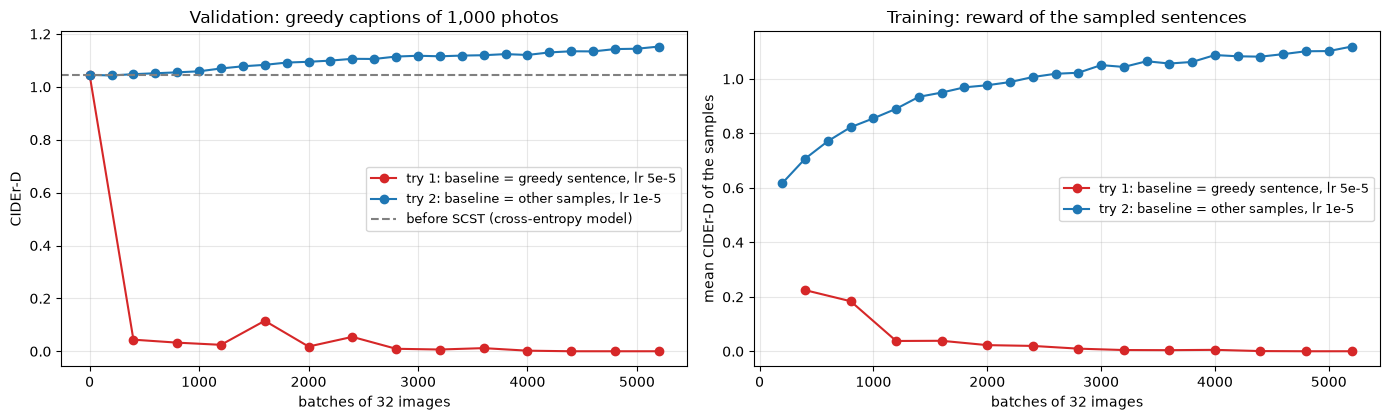

,BLEU-1,BLEU-2,BLEU-3,BLEU-4,distinct captions,mean length,CIDEr-D,repeated 2-gram (%)
Human (one caption vs the 4 others),0.629,0.433,0.288,0.190,4965.0,10.441,0.883,3.44
"Section 7: first model (12,000 images)",0.608,0.415,0.274,0.180,2896.0,9.758,0.642,23.00
11.1: all of COCO (InceptionV3),0.646,0.461,0.317,0.216,3108.0,9.794,0.802,12.74
11.2: EfficientNetV2-S,0.660,0.475,0.329,0.229,3356.0,9.692,0.850,11.34
11.2: ConvNeXt-Large,0.689,0.510,0.360,0.253,3881.0,9.968,0.980,12.54
"11.2: ConvNeXt-Large, training continued",0.698,0.520,0.373,0.264,3840.0,9.916,1.009,15.08
11.3: greedy (as before),0.698,0.520,0.373,0.264,3840.0,9.916,1.009,15.08
"11.3: beam 3, no repeated 2-gram",0.710,0.534,0.393,0.289,3398.0,9.317,1.061,0.00
"11.4: SCST, greedy",0.726,0.554,0.406,0.296,3227.0,9.261,1.116,11.98
"11.4: SCST, beam 3, no repeated 2-gram",0.728,0.559,0.411,0.301,2933.0,8.995,1.140,0.00


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
runs = [("try 2: baseline = other samples, lr 1e-5", scst_log, "tab:blue")]
if len(scst_runs) > 1:
    runs.insert(0, ("try 1: baseline = greedy sentence, lr 5e-5", hist_of(scst_runs[0]), "tab:red"))
for label, log, colour in runs:
    axes[0].plot(log["step"], log["val_cider"], marker="o", color=colour, label=label)
    axes[1].plot(log["step"][1:], log["train_reward"], marker="o", color=colour, label=label)
axes[0].axhline(scst_log["val_cider"][0], color="grey", ls="--", label="before SCST (cross-entropy model)")
axes[0].set(xlabel="batches of 32 images", ylabel="CIDEr-D", title="Validation: greedy captions of 1,000 photos")
axes[1].set(xlabel="batches of 32 images", ylabel="mean CIDEr-D of the samples",
            title="Training: reward of the sampled sentences")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

for name, (k, nr) in [("11.4: SCST, greedy", (1, 0)), (f"11.4: SCST, {BEST_DECODING}", DECODINGS[BEST_DECODING])]:
    caps = test_captions(SCST_WEIGHTS, k, nr)
    compare(name, [caps[i] for i in fair])
    comparison[name]["CIDEr-D"] = cider_d(refs_fair, comparison_caps[name])
table = pd.DataFrame(comparison).T
table["repeated 2-gram (%)"] = [repeats(comparison_caps[n]) for n in table.index]
table.to_csv("reports/d3_improvements_5000_test_photos.csv")
table.round(3)

**Reading.** Try 2 works. The validation CIDEr-D (greedy captions of 1,000 validation photos) rises from 1.045 to
1.152 after 5,200 batches, without the collapse of try 1 (red curve). The reward of the sampled
sentences rises with it: the network learns to write, on its own, sentences that the score prefers.

On the same 5,000 test photos: with greedy decoding, SCST gives BLEU-4 0.296 and CIDEr-D 1.116 against
0.264 and 1.009 for the cross-entropy model; with beam 3, no repeated 2-gram, BLEU-4 0.301 and CIDEr-D 1.140 against
0.289 and 1.061. SCST and beam search add up. The lesson of try 1: a reinforcement-learning loss can destroy what
the network learned in a few hundred batches; the baseline and the learning rate are what keep it stable, and the
validation curve is what shows it.

## 12. The final model

### 12.1 Choice on validation

Four candidates: the cross-entropy model (11.2) or the SCST model (11.4), each with greedy decoding or with the
decoding chosen in 12.3. The final model is the best **validation** CIDEr-D (2,000 validation photos, 5 human
captions each). The test split has not been used for any choice.

In [29]:
CANDIDATES = {"cross-entropy, greedy": (XE_WEIGHTS, 1, 0),
              f"cross-entropy, {BEST_DECODING}": (XE_WEIGHTS, *DECODINGS[BEST_DECODING]),
              "SCST, greedy": (SCST_WEIGHTS, 1, 0),
              f"SCST, {BEST_DECODING}": (SCST_WEIGHTS, *DECODINGS[BEST_DECODING])}
rows = {}
for name, (w, k, nr) in CANDIDATES.items():
    caps = val_captions(w, k, nr)
    rows[name] = {"BLEU-4": corpus_bleu(refs_val, caps)["BLEU-4"], "CIDEr-D": cider_d(refs_val, caps)}
final_choice = pd.DataFrame(rows).T
FINAL = final_choice["CIDEr-D"].idxmax()
FINAL_WEIGHTS, FINAL_K, FINAL_NO_REPEAT = CANDIDATES[FINAL]
final_choice.to_csv("reports/d3_final_choice_val.csv")
print(f"VALIDATION ({N_VAL} photos) -> final model: {FINAL} ({FINAL_WEIGHTS.name})")
final_choice.round(4)

VALIDATION (2000 photos) -> final model: SCST, beam 3, no repeated 2-gram (d3_captioner_convnextl_scst_20261022_090648.weights.h5)


,BLEU-4,CIDEr-D
"cross-entropy, greedy",0.3114,1.0769
"cross-entropy, beam 3, no repeated 2-gram",0.3449,1.1507
"SCST, greedy",0.3529,1.1984
"SCST, beam 3, no repeated 2-gram",0.3604,1.2218


### 12.2 Complete architecture of the final model

Same network as in section 3, with the numbers of the final pre-processing CNN: **ConvNeXt-Large**, a classification
CNN pre-trained on ImageNet (first on the 14 million images and 21,841 classes of ImageNet-22k, then on the 1,000
classes of ImageNet-1k), used **frozen and without its classification head**. Its last stage gives a 9x9 grid of
1536 numbers: **81 regions**, each one describing a zone of the image (objects, textures, context). The CNN runs once
per image, before training; the trained network (green, orange, purple, red) never sees the pixels.

ConvNeXt (Liu et al., 2022) is a CNN modernised with the ideas of vision transformers: 7x7 depthwise convolutions,
layer normalisation, GELU activations, inverted bottlenecks, 4 stages (3, 3, 27, 3 blocks) that divide the image size
by 32 (288 -> 9). It stays a pure convolutional network.

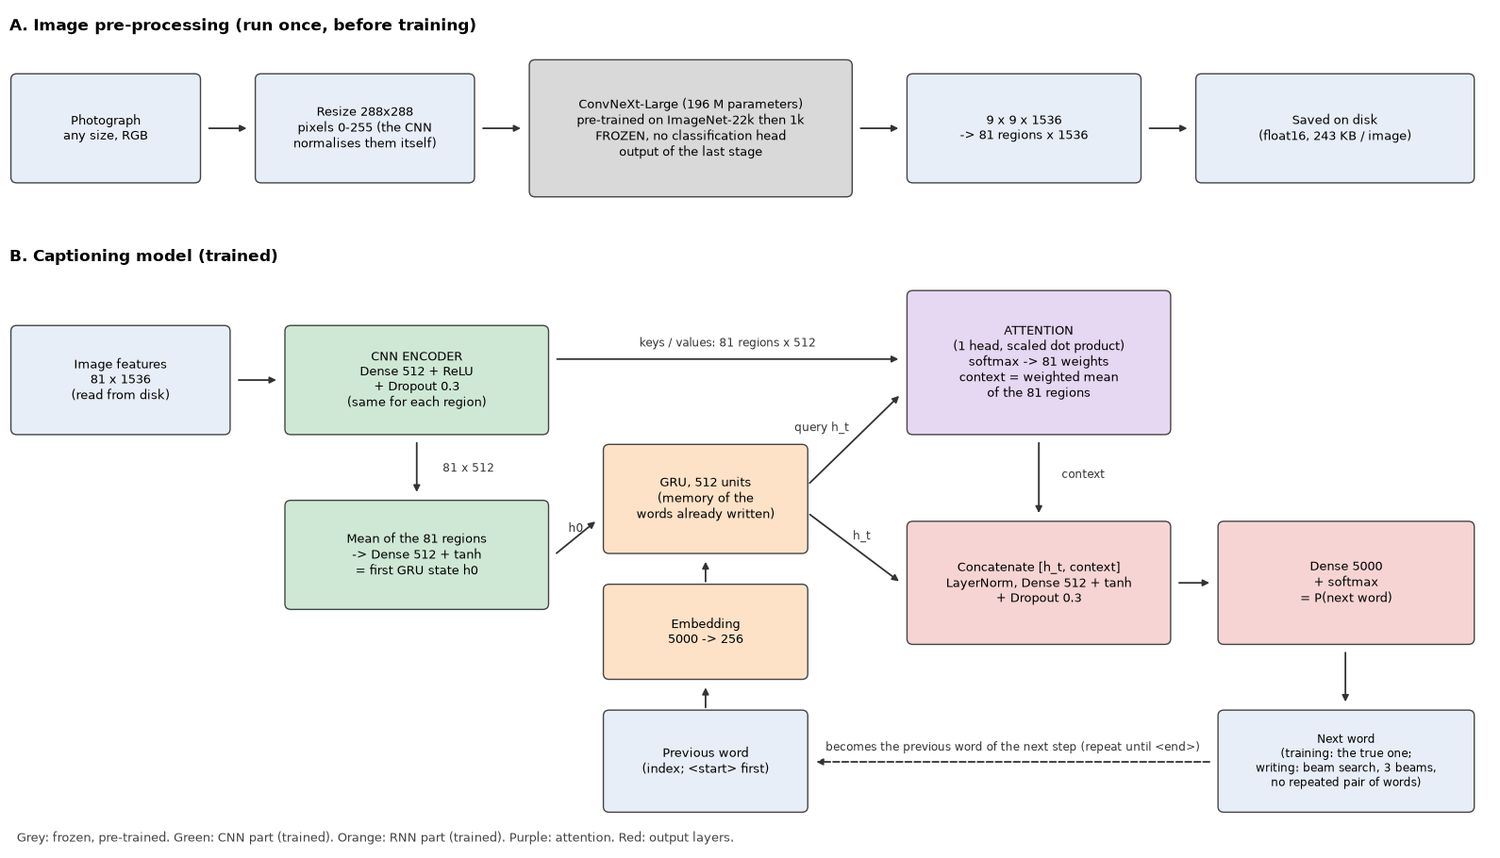

In [30]:
def draw_architecture_final():
    # Schematic diagram of the whole network (matplotlib only: no graphviz needed).
    fig, ax = plt.subplots(figsize=(16, 9.2))
    ax.set_xlim(0, 100); ax.set_ylim(0, 60); ax.axis("off")
    colours = {"data": "#e8eef7", "frozen": "#d9d9d9", "cnn": "#cfe8d5", "rnn": "#fde2c8", "att": "#e6d7f2", "out": "#f7d4d4"}

    def box(x, y, w, h, text, kind, size=9.5):
        ax.add_patch(matplotlib.patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.4",
                                                       fc=colours[kind], ec="#444444", lw=1))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=size)

    def arrow(x1, y1, x2, y2, text="", style="-|>", ls="-", rad=0.0, offset=(0, 0.9)):
        ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle=style, lw=1.3, color="#333333", ls=ls,
                                                             connectionstyle=f"arc3,rad={rad}"))
        if text:
            ax.text((x1 + x2) / 2 + offset[0], (y1 + y2) / 2 + offset[1], text, ha="center", fontsize=8.5, color="#333333")

    # Top row: pre-processing, run once.
    ax.text(0, 58.5, "A. Image pre-processing (run once, before training)", fontsize=12, weight="bold")
    box(0.5, 48, 12, 7, "Photograph\nany size, RGB", "data")
    box(17, 48, 14, 7, "Resize 288x288\npixels 0-255 (the CNN\nnormalises them itself)", "data")
    box(35.5, 47, 21, 9, "ConvNeXt-Large (196 M parameters)\npre-trained on ImageNet-22k then 1k\nFROZEN, no classification head\noutput of the last stage", "frozen")
    box(61, 48, 15, 7, "9 x 9 x 1536\n-> 81 regions x 1536", "data")
    box(80.5, 48, 18, 7, "Saved on disk\n(float16, 243 KB / image)", "data")
    arrow(13.3, 51.5, 16.2, 51.5); arrow(31.8, 51.5, 34.7, 51.5); arrow(57.3, 51.5, 60.2, 51.5); arrow(76.8, 51.5, 79.7, 51.5)

    # Bottom: the trained model.
    ax.text(0, 42, "B. Captioning model (trained)", fontsize=12, weight="bold")
    box(0.5, 30, 14, 7, "Image features\n81 x 1536\n(read from disk)", "data")
    box(19, 30, 17, 7, "CNN ENCODER\nDense 512 + ReLU\n+ Dropout 0.3\n(same for each region)", "cnn")
    box(19, 17.5, 17, 7, "Mean of the 81 regions\n-> Dense 512 + tanh\n= first GRU state h0", "cnn")
    arrow(15.3, 33.5, 18.2, 33.5)
    arrow(27.5, 29.2, 27.5, 25.3, "81 x 512", offset=(3.5, -0.3))

    box(40.5, 3, 13, 6.5, "Previous word\n(index; <start> first)", "data")
    box(40.5, 12.5, 13, 6, "Embedding\n5000 -> 256", "rnn")
    box(40.5, 21.5, 13, 7, "GRU, 512 units\n(memory of the\nwords already written)", "rnn")
    arrow(47, 9.9, 47, 11.7); arrow(47, 18.9, 47, 20.7)
    arrow(36.8, 21, 39.7, 23.5, "h0", offset=(0, 0.4))
    arrow(53.9, 26, 60.2, 32.5, "query h_t", offset=(-2.2, 0.6))
    box(61, 30, 17, 9.5, "ATTENTION\n(1 head, scaled dot product)\nsoftmax -> 81 weights\ncontext = weighted mean\nof the 81 regions", "att", 9)
    arrow(36.8, 35, 60.2, 35, "keys / values: 81 regions x 512", offset=(0, 0.9))

    box(61, 15, 17, 8, "Concatenate [h_t, context]\nLayerNorm, Dense 512 + tanh\n+ Dropout 0.3", "out")
    arrow(69.5, 29.2, 69.5, 23.8, "context", offset=(3, 0))
    arrow(53.9, 24, 60.2, 19, "h_t", offset=(0.5, 0.6))
    box(82, 15, 16.5, 8, "Dense 5000\n+ softmax\n= P(next word)", "out")
    arrow(78.8, 19, 81.2, 19)
    box(82, 3, 16.5, 6.5, "Next word\n(training: the true one;\nwriting: beam search, 3 beams,\nno repeated pair of words)", "data", 8.5)
    arrow(90.2, 14.2, 90.2, 10.3)
    arrow(81.2, 6.2, 54.3, 6.2, "becomes the previous word of the next step (repeat until <end>)", ls="--", offset=(0, 0.8))
    ax.text(0.5, 0.5, "Grey: frozen, pre-trained. Green: CNN part (trained). Orange: RNN part (trained). "
            "Purple: attention. Red: output layers.", fontsize=9, color="#444444")
    plt.tight_layout()
    plt.show()


draw_architecture_final()

### 12.3 Image and text pre-processing of the final model

**Image.** The photo is read in RGB, resized to **288x288** (bilinear with antialiasing, no crop: the whole image is
kept, wide images are squashed), pixels left in **0-255** (the Keras ConvNeXt does its own normalisation), then goes
through the frozen ConvNeXt-Large. The 9x9x1536 output is stored as **81 regions x 1536** numbers in 16-bit floats
(243 KB per image, 31 GB for the 123,287 images), computed once in mixed precision, 4 images at a time on the 2 GB GPU
(27 minutes in total). Training then reads the features from disk instead of running a 196-million-parameter CNN
at every epoch.

**Text.** Same rules as section 5, on the 431,730 captions of the 86,301 training images: lower case, letters only,
`<start>` and `<end>` added, captions longer than 20 words left out (0.6 %), the **5,000 most frequent words** kept
(98.7 % of the word occurrences; the others become `<unk>`), each caption = 22 indexes padded with `<pad>`. Only the
training captions are used to build the vocabulary.

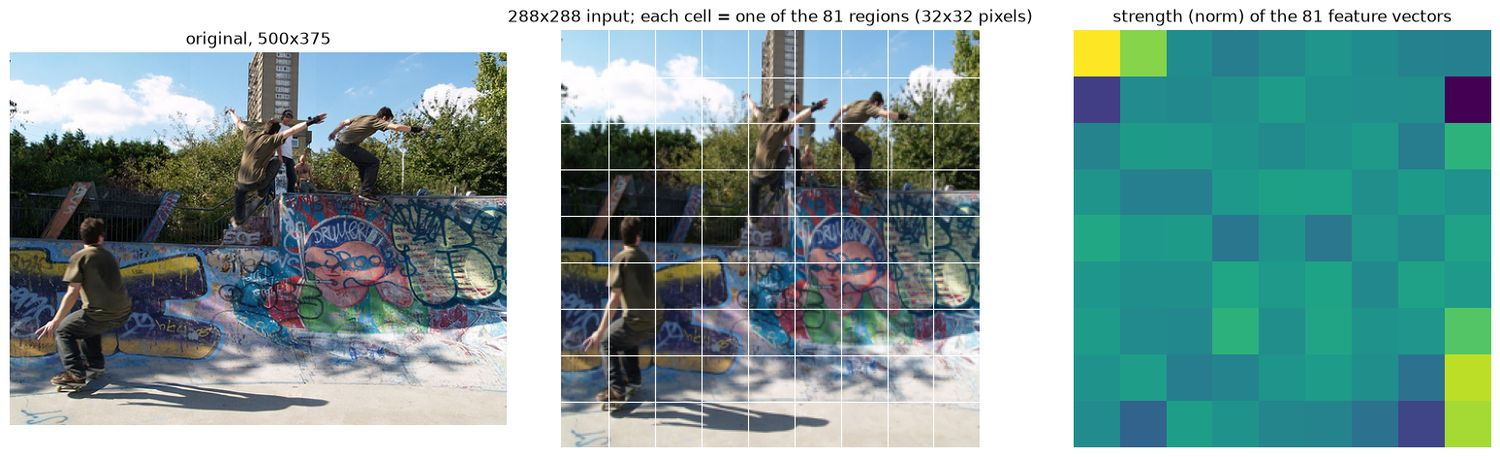

features of this photo: (81, 1536), stored as float16 (243 KB), values in [-25.2, 28.0]
caption      : A young man riding a skateboard into the air.
cleaned      : ['a', 'young', 'man', 'riding', 'a', 'skateboard', 'into', 'the', 'air']
indexes (22) : [2, 4, 49, 12, 47, 4, 90, 154, 7, 121, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
decoder input: ['<start>', 'a', 'young', 'man', 'riding', 'a', 'skateboard', 'into', 'the', 'air', '<end>'] 
target       : ['a', 'young', 'man', 'riding', 'a', 'skateboard', 'into', 'the', 'air', '<end>']


In [31]:
from PIL import Image

i = fair[0]
img = Image.open(image_path(split["test"][i])).convert("RGB")
small = np.asarray(img.resize((288, 288), Image.BILINEAR))
f = np.asarray(feats_cnx["test"][i], np.float32)                # (81, 1536): what the decoder receives
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].imshow(img); axes[0].set_title(f"original, {img.size[0]}x{img.size[1]}")
axes[1].imshow(small)
for g in range(1, 9):
    axes[1].axhline(g * 32, color="white", lw=0.8); axes[1].axvline(g * 32, color="white", lw=0.8)
axes[1].set_title("288x288 input; each cell = one of the 81 regions (32x32 pixels)")
axes[2].imshow(np.linalg.norm(f, axis=1).reshape(9, 9), cmap="viridis"); axes[2].set_title("strength (norm) of the 81 feature vectors")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"features of this photo: {f.shape}, stored as {feats_cnx['test'].dtype} ({feats_cnx['test'][i].nbytes / 1024:.0f} KB), "
      f"values in [{f.min():.1f}, {f.max():.1f}]")

words = clean(split["test"][i]["captions"][0])
ids = encode(words)
print("caption      :", split["test"][i]["captions"][0].strip())
print("cleaned      :", words)
print("indexes (22) :", ids)
print("decoder input:", [vocab[j] for j in ids[:-1] if j], "\ntarget       :", [vocab[j] for j in ids[1:] if j])

### 12.4 The code of the CNN and of the RNN

The code is the one of section 6 (`build_captioner`), unchanged: only the input size changed, 81 regions of 1536
numbers instead of 64 of 2048. In short:

- **CNN part (encoder)**: the frozen ConvNeXt-Large (pre-processing, outside the model), then a `Dense(512) + ReLU`
  applied to each region, which **learns** to bring the ImageNet features to the language of the captions.
- **RNN part (decoder)**: an `Embedding` (word -> 256 numbers), a `GRU` of 512 units started from the mean of the
  regions, an **attention** layer (at each word, the GRU state chooses which of the 81 regions to look at), and the
  output layers (`LayerNorm`, `Dense(512) + tanh`, `Dense(5000)` = one score per word of the vocabulary).
- Training (11.2): cross-entropy on the next word (Adam, learning rate 1e-3, gradient clipped to norm 1, dropout 0.3,
  early stopping); then (11.4) SCST on the CIDEr-D of whole sentences.

In [32]:
captioner.load_weights(FINAL_WEIGHTS)
captioner.summary()
parts = {"CNN part (Dense on each region + initial state)": ["encoder_dense", "initial_state"],
         "RNN part (embedding + GRU)": ["embedding", "gru"], "attention": ["attention"],
         "output (LayerNorm + Dense 512 + Dense 5000)": ["normalise", "combine", "next_word_scores"]}
n_params = {p: sum(captioner.get_layer(n).count_params() for n in names) for p, names in parts.items()}
n_params["frozen ConvNeXt-Large (pre-processing, not in this model)"] = 196_230_336
pd.Series(n_params, name="parameters").to_frame().style.format("{:,}")

Model: "captioner"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_features      │ (None, 81, 1536)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dense       │ (None, 81, 512)   │    786,944 │ image_features[0… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dropout     │ (None, 81, 512)   │          0 │ encoder_dense[0]… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ previous_words      │ (None, 21)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mean_of_regions     │ (None, 512)       │          0 │ encoder_dropout[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 21, 256)   │  1,280,000 │ previous_words[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ initial_state       │ (None, 512)       │    262,656 │ mean_of_regions[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 21, 512)   │  1,182,720 │ embedding[0][0],  │
│                     │                   │            │ initial_state[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, 21, 512), │    525,568 │ encoder_dropout[… │
│ (MultiHeadAttentio… │ (None, 1, 21,     │            │ gru[0][0],        │
│                     │ 21)]              │            │ encoder_dropout[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ state_and_context   │ (None, 21, 1024)  │          0 │ gru[0][0],        │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalise           │ (None, 21, 1024)  │      2,048 │ state_and_contex… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combine             │ (None, 21, 512)   │    524,800 │ normalise[0][0]   │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_dropout      │ (None, 21, 512)   │          0 │ combine[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_word_scores    │ (None, 21, 5000)  │  2,565,000 │ output_dropout[0… │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,129,736 (27.20 MB)

 Trainable params: 7,129,736 (27.20 MB)

 Non-trainable params: 0 (0.00 B)

,parameters
CNN part (Dense on each region + initial state),"1,049,600"
RNN part (embedding + GRU),"2,462,720"
attention,"525,568"
output (LayerNorm + Dense 512 + Dense 5000),"3,091,848"
"frozen ConvNeXt-Large (pre-processing, not in this model)","196,230,336"


### 12.5 Training curves of the final model

Left and middle: the cross-entropy training (section 11.2), 30 epochs then the continuation (after the dotted line).
The weights kept are those of the best epoch of the continuation (lowest validation loss after the dotted line),
preferred to epoch 29 by the validation BLEU-4 (11.2). Right: the SCST fine-tuning (section 11.4).

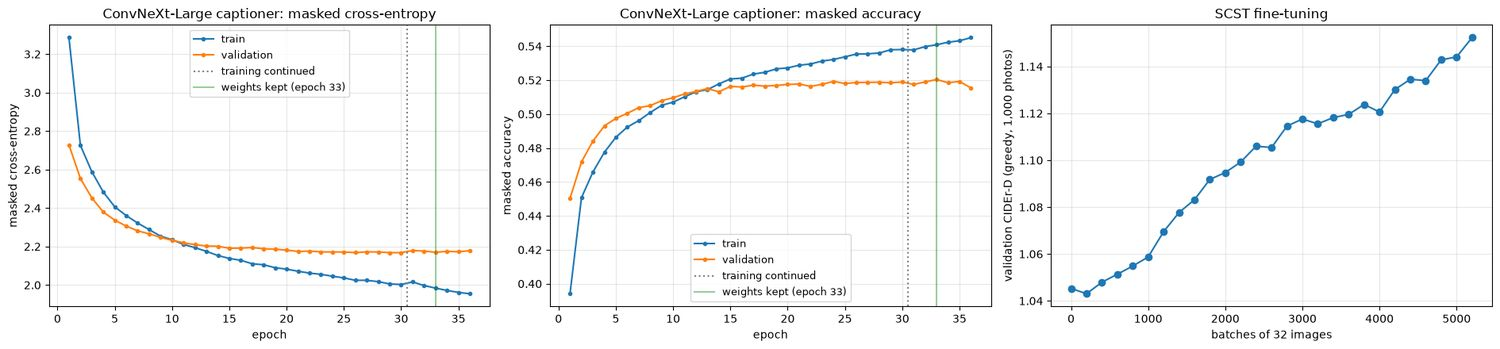

cross-entropy, weights of epoch 33/36: train loss 1.984 | val loss 2.170 | train accuracy 0.541 | val accuracy 0.520 | 61 min of training


In [33]:
h = history_final
ep = np.arange(1, len(h["loss"]) + 1)
n_first = len(history_cnx["loss"])
best = n_first + int(np.argmin(h["val_loss"][n_first:]))   # best epoch of the continuation = weights kept
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
for ax, metric, label in [(axes[0], "loss", "masked cross-entropy"), (axes[1], "masked_accuracy", "masked accuracy")]:
    ax.plot(ep, h[metric], marker="o", ms=3, label="train")
    ax.plot(ep, h[f"val_{metric}"], marker="o", ms=3, label="validation")
    ax.axvline(n_first + 0.5, color="grey", ls=":", label="training continued")
    ax.axvline(best + 1, color="green", alpha=0.4, label=f"weights kept (epoch {best + 1})")
    ax.set(xlabel="epoch", ylabel=label, title=f"ConvNeXt-Large captioner: {label}")
    ax.grid(alpha=0.3); ax.legend(fontsize=9)
axes[2].plot(scst_log["step"], scst_log["val_cider"], marker="o", color="tab:blue")
axes[2].set(xlabel="batches of 32 images", ylabel="validation CIDEr-D (greedy, 1,000 photos)", title="SCST fine-tuning")
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"cross-entropy, weights of epoch {best + 1}/{len(ep)}: train loss {h['loss'][best]:.3f} | val loss {h['val_loss'][best]:.3f} | "
      f"train accuracy {h['masked_accuracy'][best]:.3f} | val accuracy {h['val_masked_accuracy'][best]:.3f} | "
      f"{h['seconds'] / 60:.0f} min of training")

### 12.6 Final test: the whole 15 % test split (18,493 photos)

Every photo of the test split, none used to train or to choose anything. Each caption is scored against **4** human
captions; the 5th human caption is scored the same way and gives the "human" row, the agreement between two people.
The four candidates of 13.1 are all shown; the final model is the one chosen on validation.

In [34]:
test_im = split["test"]
refs_test = [[clean(c) for c in im["captions"][1:]] for im in test_im]
human = [clean(im["captions"][0]) for im in test_im]
caps_by = {name: test_captions(w, k, nr) for name, (w, k, nr) in CANDIDATES.items()}
caps_by["Human (one caption vs the other 4)"] = human
rows, per_image = {}, {}
for name, caps in caps_by.items():
    per_image[name] = cider_d_per_image(refs_test, caps)
    rows[name] = {**corpus_bleu(refs_test, caps), "CIDEr-D": per_image[name].mean(),
                  "distinct captions": len({" ".join(c) for c in caps}), "repeated 2-gram (%)": repeats(caps),
                  "mean length (words)": np.mean([len(c) for c in caps])}
final_table = pd.DataFrame(rows).T
final_table.index = [f"{n}  <- FINAL" if n == FINAL else n for n in final_table.index]
final_table.to_csv("reports/d3_final_test_15pct.csv")
print(f"TEST, whole 15 % split: {len(test_im):,} photos, 4 human captions each")
final_table.style.format({**{c: "{:.3f}" for c in final_table.columns}, "distinct captions": "{:,.0f}",
                          "repeated 2-gram (%)": "{:.1f}", "mean length (words)": "{:.1f}"})

TEST, whole 15 % split: 18,493 photos, 4 human captions each


,BLEU-1,BLEU-2,BLEU-3,BLEU-4,CIDEr-D,distinct captions,repeated 2-gram (%),mean length (words)
"cross-entropy, greedy",0.697,0.519,0.370,0.261,0.990,"11,909",15.4,9.9
"cross-entropy, beam 3, no repeated 2-gram",0.712,0.536,0.392,0.287,1.051,"9,874",0.0,9.3
"SCST, greedy",0.725,0.553,0.405,0.294,1.099,"9,391",11.7,9.3
"SCST, beam 3, no repeated 2-gram <- FINAL",0.729,0.558,0.410,0.301,1.124,"8,217",0.0,9.0
Human (one caption vs the other 4),0.633,0.437,0.293,0.195,0.873,"18,221",3.6,10.5


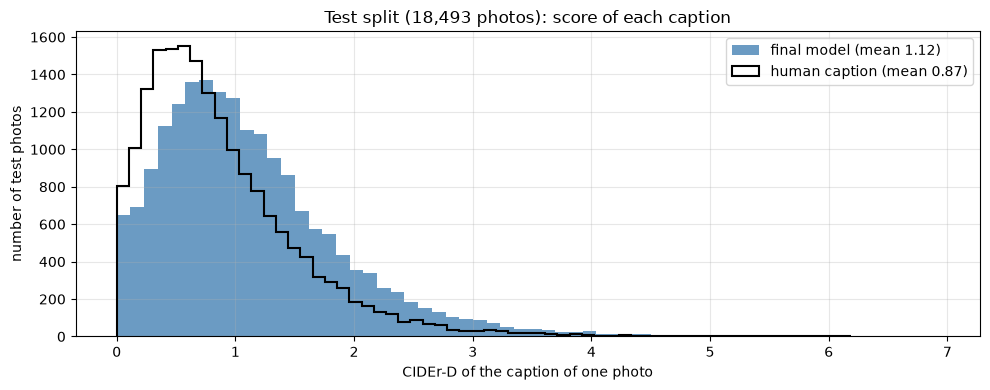

per-photo CIDEr-D of the final model: 10 % / 25 % / median / 75 % / 90 % = [0.3  0.58 0.98 1.49 2.13]
photos with CIDEr-D >= 1 (as good as a typical human caption or better): 48.6 % | below 0.3 (mostly wrong): 10.0 %


In [35]:
fc = per_image[FINAL]
q = np.quantile(fc, [0.1, 0.25, 0.5, 0.75, 0.9])
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(fc, bins=60, color="steelblue", alpha=0.8, label=f"final model (mean {fc.mean():.2f})")
ax.hist(per_image["Human (one caption vs the other 4)"], bins=60, histtype="step", color="black", lw=1.5,
        label=f"human caption (mean {per_image['Human (one caption vs the other 4)'].mean():.2f})")
ax.set(xlabel="CIDEr-D of the caption of one photo", ylabel="number of test photos",
       title=f"Test split ({len(test_im):,} photos): score of each caption")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("reports/d3_test_cider_histogram.png", dpi=80); plt.show()
print(f"per-photo CIDEr-D of the final model: 10 % / 25 % / median / 75 % / 90 % = {np.round(q, 2)}")
print(f"photos with CIDEr-D >= 1 (as good as a typical human caption or better): {100 * np.mean(fc >= 1):.1f} % | "
      f"below 0.3 (mostly wrong): {100 * np.mean(fc < 0.3):.1f} %")

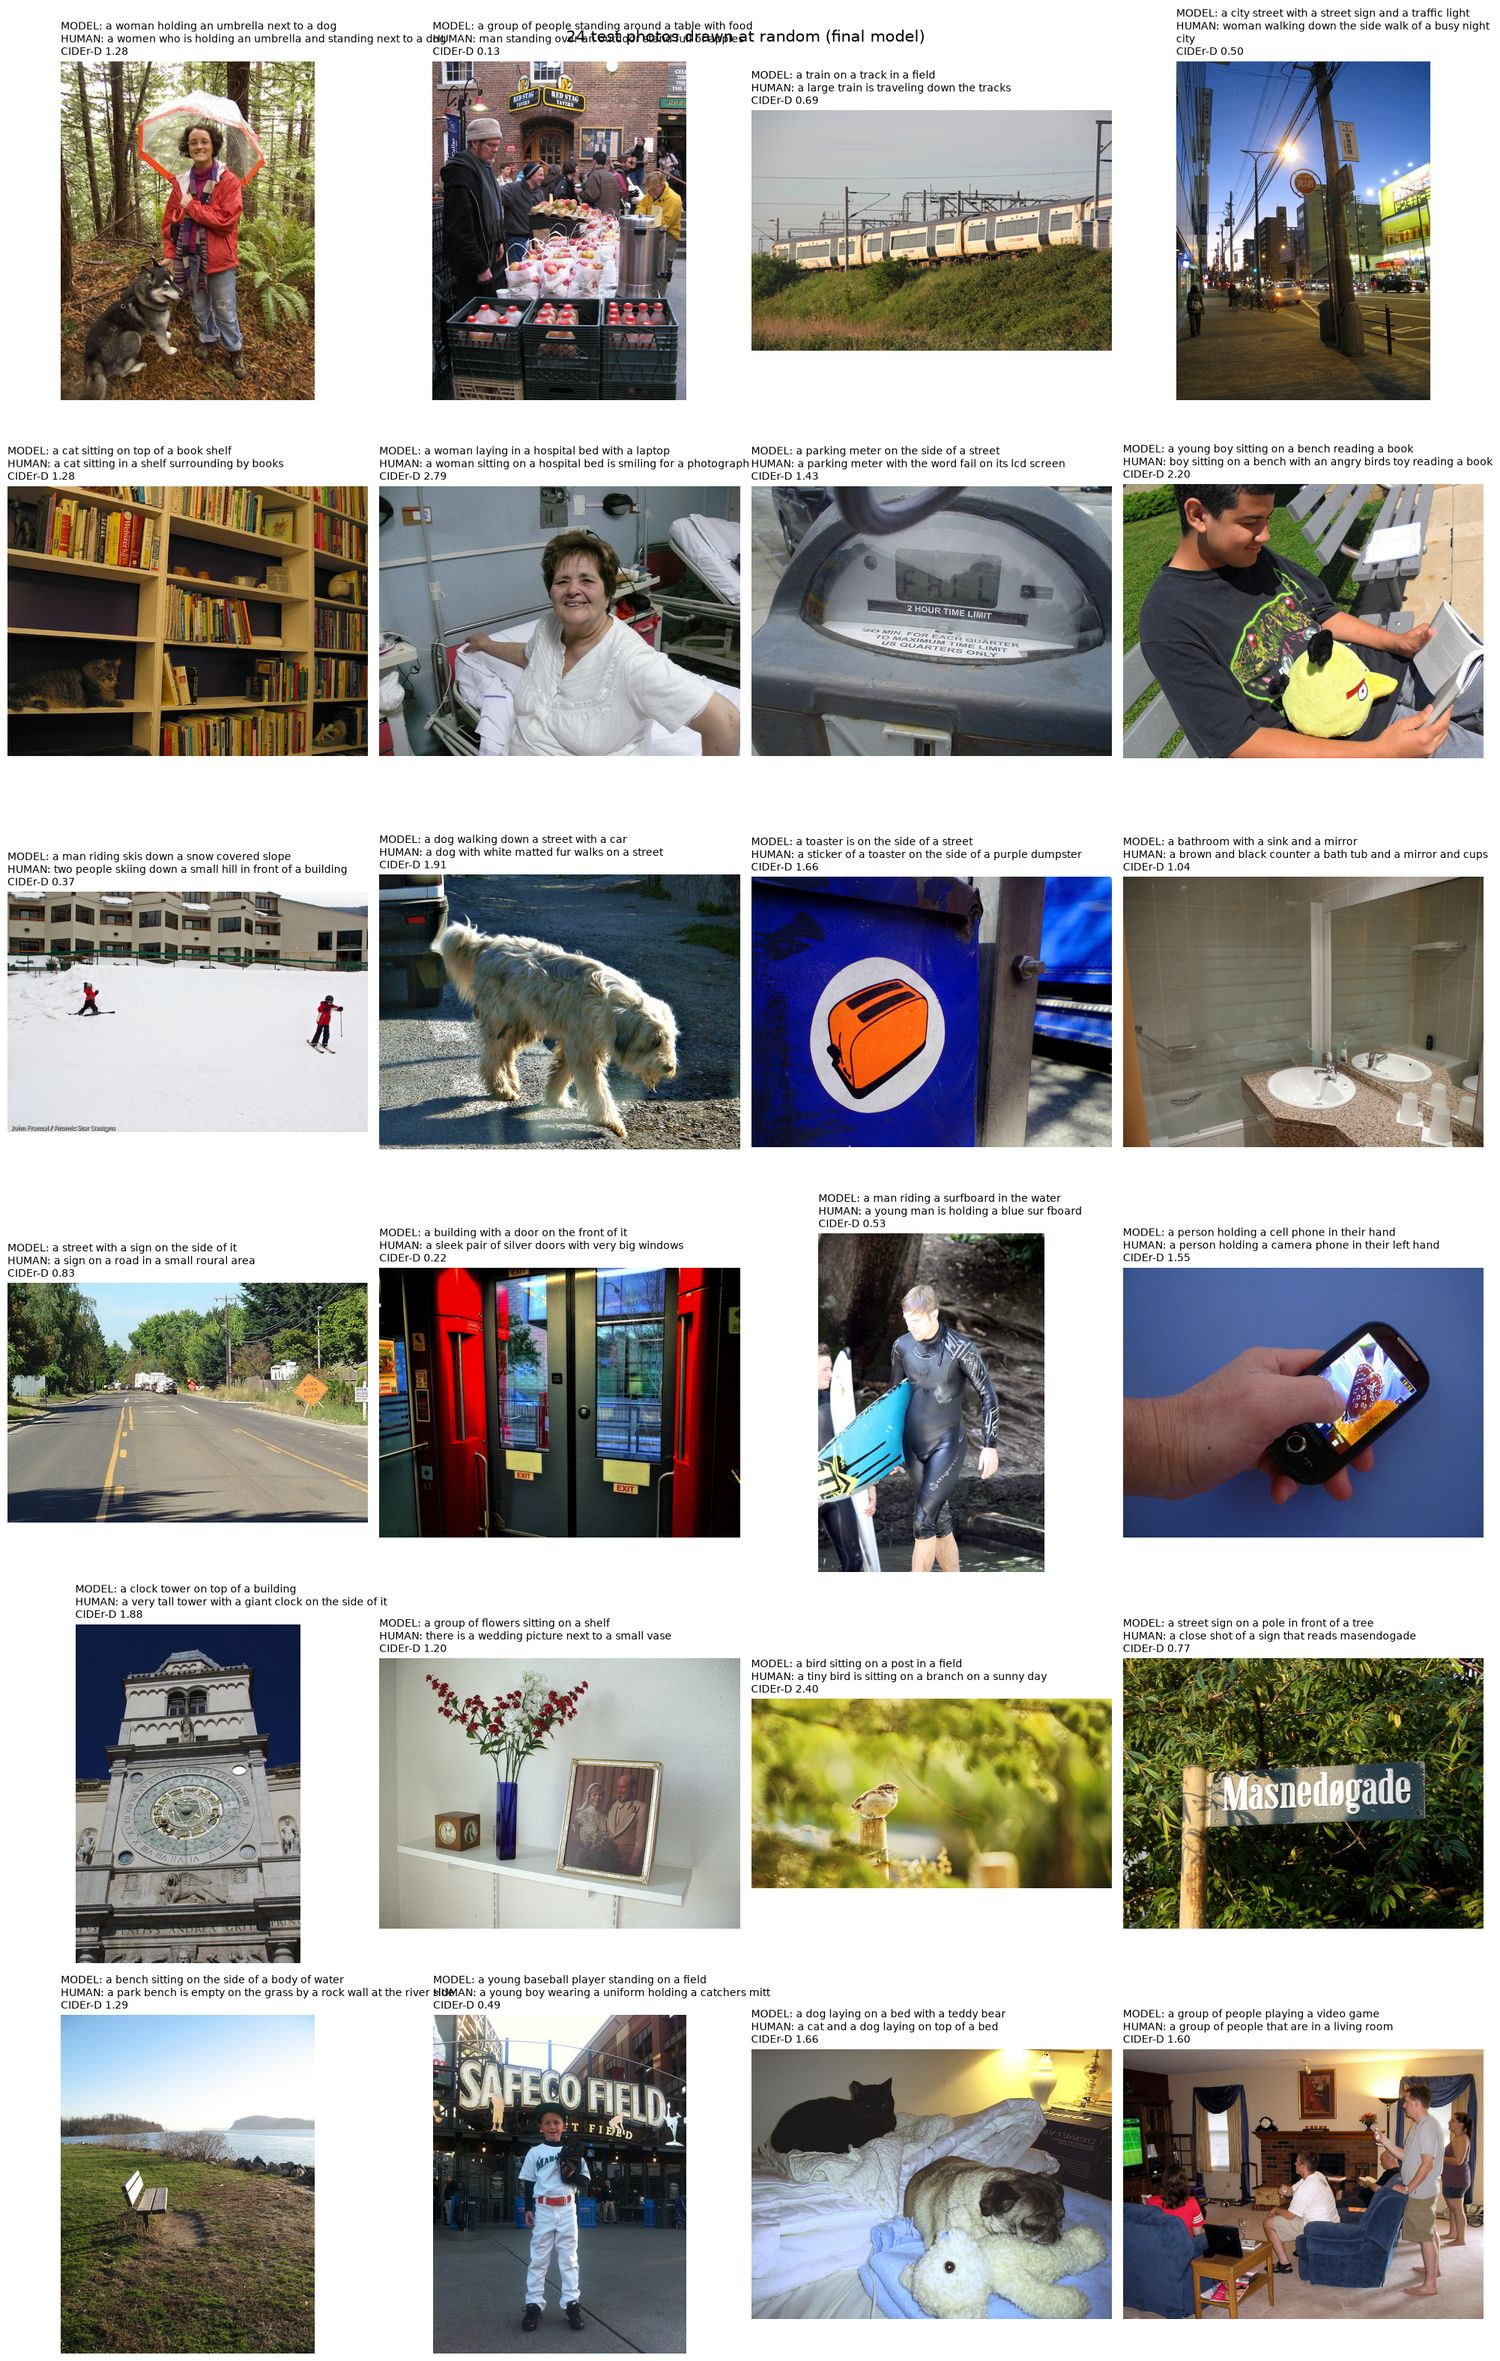

In [36]:
def gallery(indices, title, cols=4):
    n_rows = int(np.ceil(len(indices) / cols))
    fig, axes = plt.subplots(n_rows, cols, figsize=(5 * cols, 5.3 * n_rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), indices):
        ax.imshow(Image.open(image_path(test_im[i])).convert("RGB"))
        ax.set_title(f"MODEL: {' '.join(caps_by[FINAL][i])}\nHUMAN: {' '.join(human[i])}\nCIDEr-D {fc[i]:.2f}",
                     fontsize=10, loc="left", wrap=True)
    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()


random_test = sorted(np.random.default_rng(SEED).choice(len(test_im), 24, replace=False))
gallery(random_test, "24 test photos drawn at random (final model)")

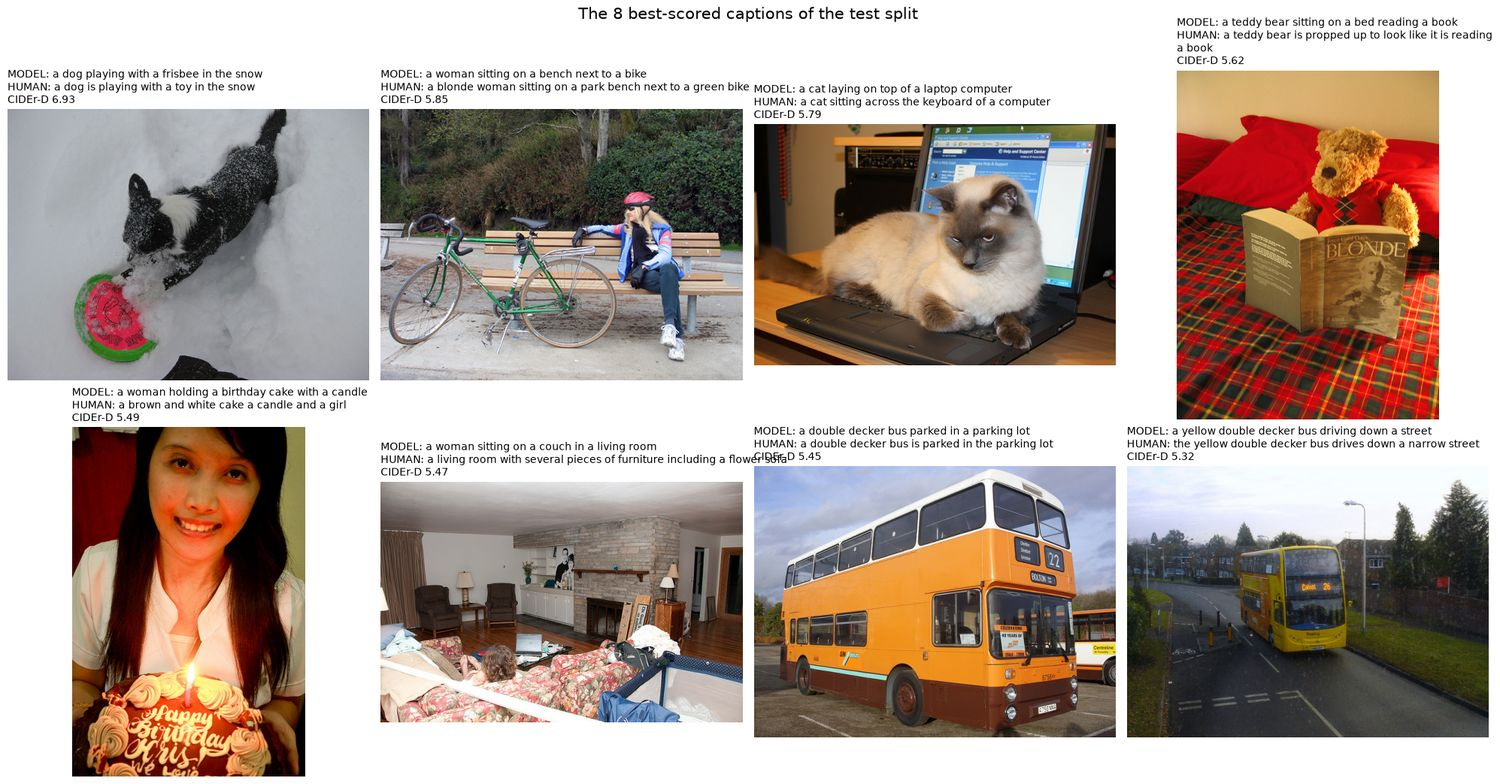

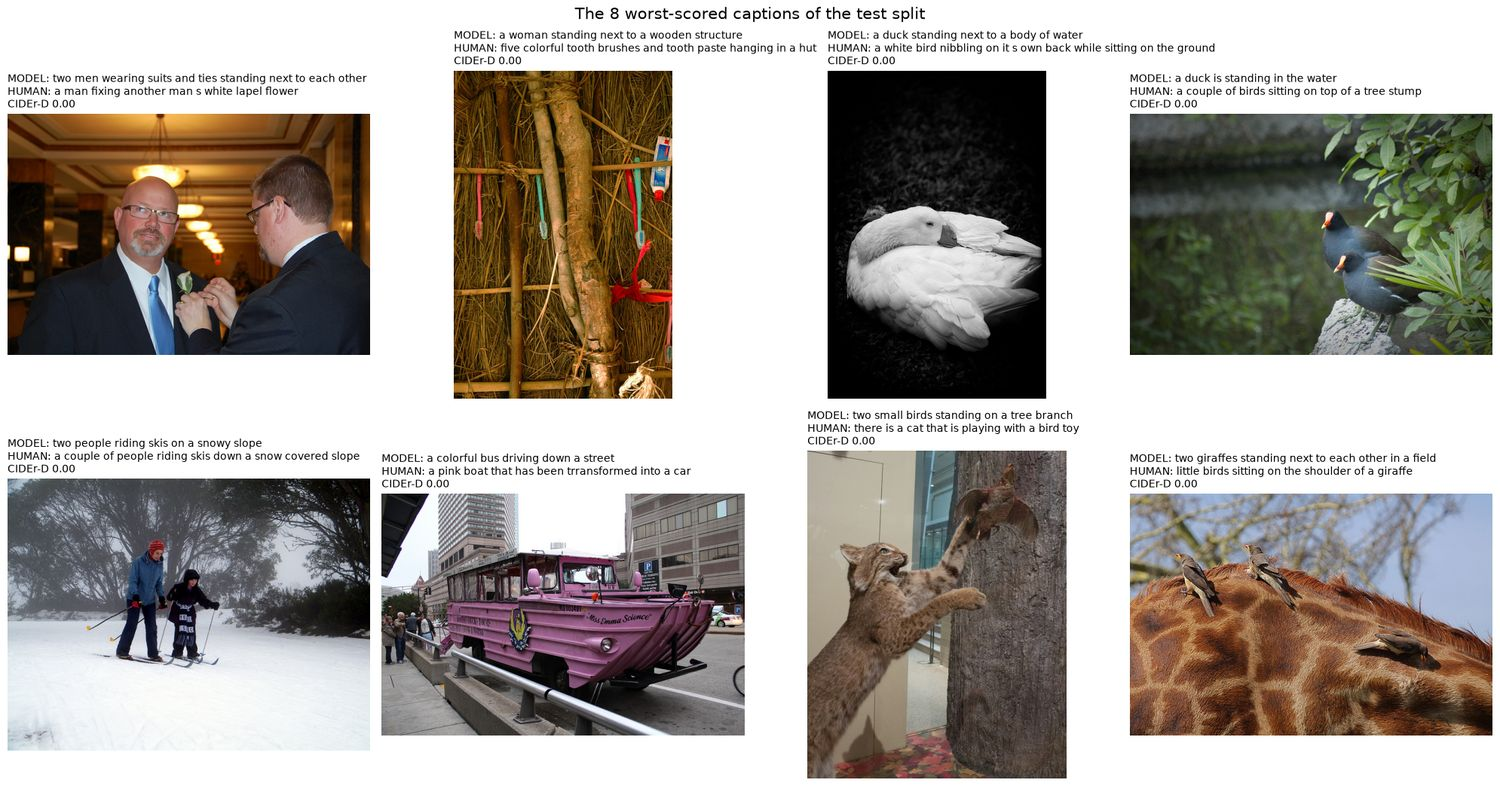

In [37]:
by_score = np.argsort(fc)
gallery(by_score[-8:][::-1], "The 8 best-scored captions of the test split")
gallery(by_score[:8], "The 8 worst-scored captions of the test split")

**Reading.** - **The final model (SCST, beam 3, no repeated 2-gram) is the best of the four candidates on the whole test split too**: BLEU-1
  0.729, BLEU-4 0.301, CIDEr-D 1.124, with no repeated pair of words. The order of the candidates on test is the
  same as on validation: the choice made on validation holds on 18,493 photos never used.
- **Against a human caption** (BLEU-4 0.195, CIDEr-D 0.873) the model scores higher, because it writes the most
  expected sentence; people write more varied and more specific ones (18,221 different captions against
  8,217, 10.5 words on average against 9.0).
- **Per photo**, the histogram shows a wide spread: many captions are as good as a human one or better (CIDEr-D >= 1),
  a minority are mostly wrong (below 0.3).
- **Galleries.** The random photos show what to expect on everyday photos: the main object, the action and the
  place are usually right, details (colours, numbers of objects) are sometimes wrong. The best-scored captions are
  common scenes described in common words. The worst-scored ones are unusual scenes, small or rare objects, or
  photos where the humans described something the model did not name.

### 12.7 Where the final model looks: attention over the 81 regions

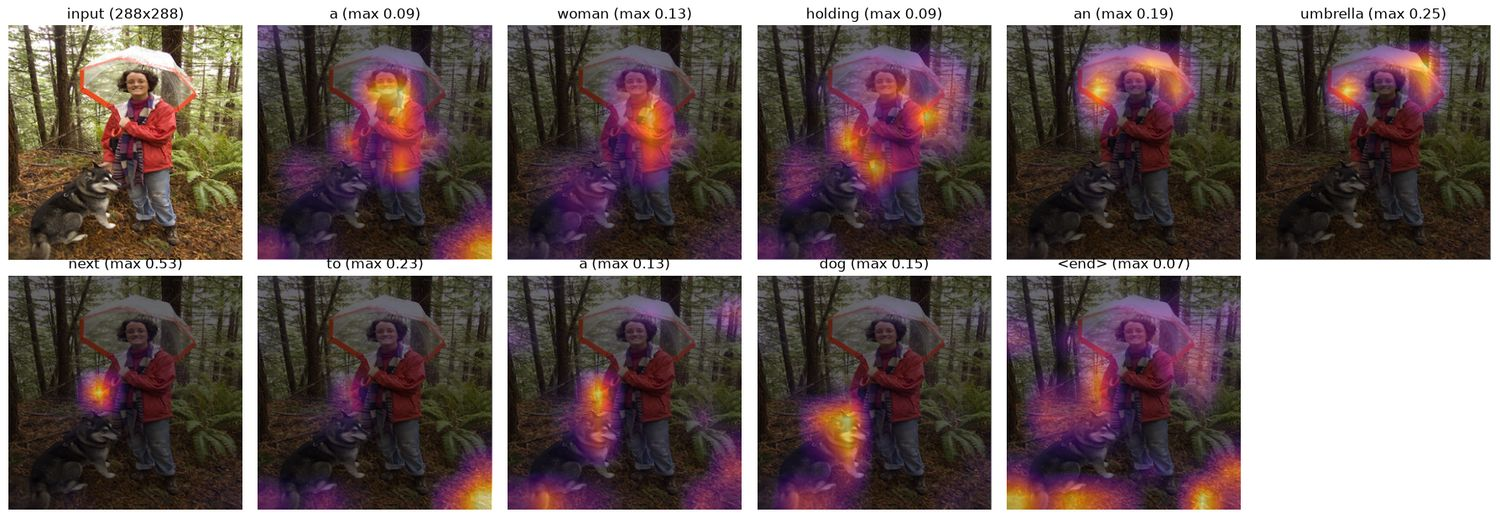

In [38]:
def show_attention_final(i):
    words = caps_by[FINAL][i][:MAX_LEN - 2]
    ids = encode(words)
    f = np.asarray(feats_cnx["test"][i:i + 1], np.float32)
    _, scores = captioner_attention.predict_on_batch([f, np.array([ids[:-1]], np.int32)])   # (1, 1, 21, 81)
    img = np.asarray(Image.open(image_path(test_im[i])).convert("RGB").resize((288, 288)))
    shown_words = words + [END]
    n_cols = 6
    n_rows = int(np.ceil((len(shown_words) + 1) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3.1 * n_rows))
    axes = axes.ravel()
    axes[0].imshow(img); axes[0].set_title("input (288x288)")
    for t, word in enumerate(shown_words):
        weights = scores[0, 0, t].reshape(9, 9)   # the 81 weights used to choose this word
        axes[t + 1].imshow(img)
        axes[t + 1].imshow(weights, cmap="inferno", alpha=0.6, extent=(0, 288, 288, 0), interpolation="bilinear")
        axes[t + 1].set_title(f"{word} (max {weights.max():.2f})")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


captioner.load_weights(FINAL_WEIGHTS)
show_attention_final(random_test[0])

### 12.8 Saving the final model for the workflow

The final captioner is saved as one Keras file with its vocabulary and a configuration file (encoder, sizes,
decoding, test scores). Section 13 and `pipeline.ipynb` load these files and nothing else.

In [39]:
captioner.load_weights(FINAL_WEIGHTS)
captioner.save(MODELS / "d3_final_captioner.keras")
(MODELS / "d3_final_vocab.json").write_text(json.dumps(vocab))
final_row = final_table.loc[f"{FINAL}  <- FINAL"]
D3_CONFIG = {"encoder": "ConvNeXtLarge (ImageNet-22k then 1k, frozen, include_top=False)", "encoder_input": 288,
             "regions": N_REGIONS, "feature_dim": FEATURE_DIM, "max_len": MAX_LEN, "vocab_size": VOCAB_SIZE,
             "training": "cross-entropy then SCST" if FINAL.startswith("SCST") else "cross-entropy",
             "beam": int(FINAL_K), "no_repeat_ngram": int(FINAL_NO_REPEAT), "weights_from": FINAL_WEIGHTS.name,
             "trained_on": f"MS COCO 2017, {len(split['train']):,} images (70/15/15 split, seed {SEED})",
             "test_photos": len(test_im), "test_bleu4": round(float(final_row["BLEU-4"]), 3),
             "test_cider_d": round(float(final_row["CIDEr-D"]), 3)}
(MODELS / "d3_final_config.json").write_text(json.dumps(D3_CONFIG, indent=2))
reloaded = keras.models.load_model(MODELS / "d3_final_captioner.keras", compile=False)
x = [np.asarray(feats_cnx["test"][:2], np.float32), np.zeros((2, MAX_LEN - 1), np.int32)]
print("saved and reloaded, same output:", np.allclose(reloaded.predict_on_batch(x), captioner.predict_on_batch(x), atol=1e-4))
print(json.dumps(D3_CONFIG, indent=2))

saved and reloaded, same output: True
{
  "encoder": "ConvNeXtLarge (ImageNet-22k then 1k, frozen, include_top=False)",
  "encoder_input": 288,
  "regions": 81,
  "feature_dim": 1536,
  "max_len": 22,
  "vocab_size": 5000,
  "training": "cross-entropy then SCST",
  "beam": 3,
  "no_repeat_ngram": 2,
  "weights_from": "d3_captioner_convnextl_scst_20261022_090648.weights.h5",
  "trained_on": "MS COCO 2017, 86,301 images (70/15/15 split, seed 42)",
  "test_photos": 18493,
  "test_bleu4": 0.301,
  "test_cider_d": 1.124
}


## 13. The whole workflow: D1, then D2, then D3

The TouNum workflow on new images, with the final model of each deliverable, loaded from `models/`:

```
 image ──► D1  photo or not?   MobileNetV2, 128x128 (deliverable1.ipynb, models/final_pretrained.keras)
            │  not a photo (probability < 0.5) ──► stop: no caption
            ▼  photo
           D2  denoising   U-Net trained on several noise levels (deliverable2.ipynb, section 8,
            │              models/d2_unet_multi_*.weights.h5)
            ▼
           D3  caption   ConvNeXt-Large (frozen) -> 81 regions -> GRU + attention, beam search (this notebook)
```

- **D1** exactly as in deliverable 1: RGB, resized to 128x128 (bilinear), pixels 0-255; a photo if its probability is
  at least 0.5. Other images stop here.
- **D2**: the U-Net of deliverable 2 is fully convolutional, so it can be applied at **288x288**, the size the
  captioning CNN reads. Denoising at 128x128 and enlarging the result would lose most of the details the caption
  needs. This is an assumption: D2 was trained on photos reduced to 128x128.
- **D3**: the final model of section 12 (ConvNeXt-Large features, decoder, beam search with 3 beams and no repeated
  pair of words). ConvNeXt-Large runs on the CPU here: the three networks do not fit together in the 2 GB GPU.
- The table gives the caption **without** and **with** D2, so the effect of the denoising is visible.
- Images are read with **imageio**; any size, any format, grey images converted to RGB.

**To run only this section** (for example on the evaluation day): run the first code cell of the notebook (imports),
the cell of section 11.3 that defines `decode`, then this section from here.

In [3]:
import gc
import urllib.request

import imageio.v3 as iio
from PIL import Image

# Free what the previous sections used: the workflow needs the GPU memory.
for name in ["captioner", "captioner_attention", "reloaded", "inception", "train_ds", "val_ds", "rollout", "train_step"]:
    globals().pop(name, None)
keras.backend.clear_session()
gc.collect()

MODELS = Path("models")
D1_PATH = MODELS / "final_pretrained.keras"
D2_SAVED = sorted(MODELS.glob("d2_unet_multi_[0-9]*.weights.h5"))
needed = [D1_PATH, MODELS / "d3_final_captioner.keras", MODELS / "d3_final_vocab.json", MODELS / "d3_final_config.json"]
missing = [str(p) for p in needed if not p.exists()] + ([] if D2_SAVED else ["models/d2_unet_multi_<date>.weights.h5"])
assert not missing, f"missing: {missing} (run deliverable1.ipynb, deliverable2.ipynb and this notebook first)"

# ---- D1: photo or not (deliverable 1) ----
d1 = keras.models.load_model(D1_PATH, compile=False)
D1_SIZE, D1_THRESHOLD = 128, 0.5


def is_photo_proba(img_u8):
    x = np.asarray(Image.fromarray(img_u8).resize((D1_SIZE, D1_SIZE), Image.BILINEAR), np.float32)[None]
    return float(d1(x, training=False).numpy().ravel()[0])


# ---- D2: denoising (deliverable 2, section 8) ----
def build_unet_any_size():
    # The U-Net of D2 (same layers in the same order as build_unet in deliverable2.ipynb), any input size.
    inputs = keras.Input((None, None, 3))
    c1 = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = keras.layers.MaxPooling2D(2)(c1)
    c2 = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = keras.layers.MaxPooling2D(2)(c2)
    c3 = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = keras.layers.MaxPooling2D(2)(c3)
    x = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)
    x = keras.layers.Concatenate()([x, c3])
    x = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)
    x = keras.layers.Concatenate()([x, c2])
    x = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)
    x = keras.layers.Concatenate()([x, c1])
    outputs = keras.layers.Conv2D(3, 3, padding="same", activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="unet_any_size")


d2 = build_unet_any_size()
d2.load_weights(D2_SAVED[-1])


def denoise(x01):
    # (H, W, 3) in [0, 1], H and W multiples of 8 -> same size.
    return np.clip(d2(x01[None], training=False).numpy()[0], 0, 1)


# ---- D3: caption (this notebook) ----
D3 = json.loads((MODELS / "d3_final_config.json").read_text())
PAD, UNK, START, END = "<pad>", "<unk>", "<start>", "<end>"
vocab = json.loads((MODELS / "d3_final_vocab.json").read_text())
word_index = {w: i for i, w in enumerate(vocab)}
VOCAB_SIZE, MAX_LEN = len(vocab), D3["max_len"]
BANNED = [word_index[PAD], word_index[UNK], word_index[START]]
captioner = keras.models.load_model(MODELS / "d3_final_captioner.keras", compile=False)   # used by decode()
ENC = D3["encoder_input"]
with tf.device("/CPU:0"):
    encoder = keras.applications.ConvNeXtLarge(include_top=False, weights="imagenet", input_shape=(ENC, ENC, 3))
encoder.trainable = False


def caption(x288):
    # (288, 288, 3) in [0, 1] -> sentence. Same pre-processing as for training: pixels 0-255, frozen ConvNeXt-Large.
    with tf.device("/CPU:0"):
        feats = tf.reshape(encoder(x288[None] * 255.0, training=False), (1, D3["regions"], D3["feature_dim"])).numpy()
    return " ".join(decode(feats, D3["beam"], D3["no_repeat_ngram"])[0])


print(f"D1: {D1_PATH.name}, {d1.count_params():,} parameters, {D1_SIZE}x{D1_SIZE}, photo if P >= {D1_THRESHOLD}")
print(f"D2: {D2_SAVED[-1].name}, {d2.count_params():,} parameters, applied at {ENC}x{ENC}")
print(f"D3: {D3['encoder']} -> {D3['regions']} x {D3['feature_dim']} | {D3['training']} | beam {D3['beam']}, "
      f"no repeated {D3['no_repeat_ngram']}-gram | test: BLEU-4 {D3['test_bleu4']}, CIDEr-D {D3['test_cider_d']}")

E0000 00:00:1792660036.895973  697435 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792660036.896213  697435 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792660036.896401  697435 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792660037.143605  697435 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792660037.143841  697435 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792660037.144051  697435 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.


D1: final_pretrained.keras, 2,259,265 parameters, 128x128, photo if P >= 0.5
D2: d2_unet_multi_20261019_100436.weights.h5, 426,979 parameters, applied at 288x288
D3: ConvNeXtLarge (ImageNet-22k then 1k, frozen, include_top=False) -> 81 x 1536 | cross-entropy then SCST | beam 3, no repeated 2-gram | test: BLEU-4 0.301, CIDEr-D 1.124


In [4]:
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}


def read_rgb(source):
    # Path or bytes -> RGB uint8 array (imageio; grey or RGBA images converted to RGB).
    return np.ascontiguousarray(iio.imread(source, mode="RGB"))


def from_folder(folder):
    return [(p.name, read_rgb(p)) for p in sorted(Path(folder).iterdir()) if p.suffix.lower() in EXTENSIONS]


def from_urls(urls):
    items = []
    for url in urls:
        try:
            data = urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"}), timeout=30).read()
            items.append((url.rsplit("/", 1)[-1][:40] or url, read_rgb(data)))
        except Exception as e:
            print(f"could not read {url}: {type(e).__name__}: {e}")
    return items


def run_workflow(items, show=12):
    # items: list of (name, RGB uint8 image). D1 -> (photos only) D2 -> D3; table and figure.
    rows, figs = [], []
    for name, img in items:
        t0 = time.time()
        p = is_photo_proba(img)
        row = {"image": name, "size": f"{img.shape[1]}x{img.shape[0]}", "P(photo) D1": round(p, 3)}
        if p < D1_THRESHOLD:
            row.update({"D1": "not a photo: stop", "caption without D2": "-", "caption after D2 (final)": "-"})
            figs.append((name, img, None, f"NOT A PHOTO\n(P(photo) = {p:.2f})"))
        else:
            x = tf.image.resize(img[None].astype(np.float32) / 255.0, [ENC, ENC], antialias=True).numpy()[0]
            clean = denoise(x)
            final = caption(clean)
            row.update({"D1": "photo", "caption without D2": caption(x), "caption after D2 (final)": final})
            figs.append((name, img, clean, final))
        row["seconds"] = round(time.time() - t0, 1)
        rows.append(row)
    table = pd.DataFrame(rows)
    display(table.style.set_properties(**{"text-align": "left"}))
    n = min(show, len(figs))
    if n:
        fig, axes = plt.subplots(n, 2, figsize=(11, 4.6 * n), squeeze=False)
        for r, (name, img, clean, text) in enumerate(figs[:n]):
            axes[r, 0].imshow(img); axes[r, 0].set_title(f"input: {name}", fontsize=10)
            if clean is None:
                axes[r, 1].text(0.5, 0.5, text, ha="center", va="center", fontsize=12, color="firebrick")
            else:
                axes[r, 1].imshow(clean); axes[r, 1].set_title(f"after D2 ({ENC}x{ENC})\n\"{text}\"", fontsize=11, color="navy")
            for ax in axes[r]:
                ax.axis("off")
        plt.tight_layout()
        plt.show()
    return table

### 13.1 Demo: a folder with every kind of input

Photos never seen by any model (picsum.photos): one clean, two noisy, one with scan-like damage (blur + JPEG + grain),
one blurred; and two images that are **not** photographs (a sketch and a diagram from the D1 dataset), which D1 must
stop before D2 and D3.

,image,size,P(photo) D1,D1,caption without D2,caption after D2 (final),seconds
0,01_clean_photo.png,640x480,0.992000,photo,a white house sitting on top of a wooden pier,a house with a wooden dock in the background,9.600000
1,02_noisy_photo.png,480x640,0.986000,photo,a woman sitting at a table with a laptop,a woman sitting on a desk with a laptop,5.200000
2,03_very_noisy_photo.png,480x640,0.897000,photo,a black and white photo of a body of water,a black and white photo of a boat on the water,5.800000
3,04_scan_damaged_photo.png,1024x768,0.998000,photo,a black and white photo of a boat on the water,a large body of water with a boat on it,5.400000
4,05_blurred_photo.png,480x640,0.589000,photo,a bench sitting on top of a wooden pier,a bench sitting on top of a wooden bench,5.200000
5,06_sketch_not_a_photo.jpg,411x583,0.135000,not a photo: stop,-,-,0.100000
6,07_diagram_not_a_photo.jpg,787x695,0.001000,not a photo: stop,-,-,0.100000


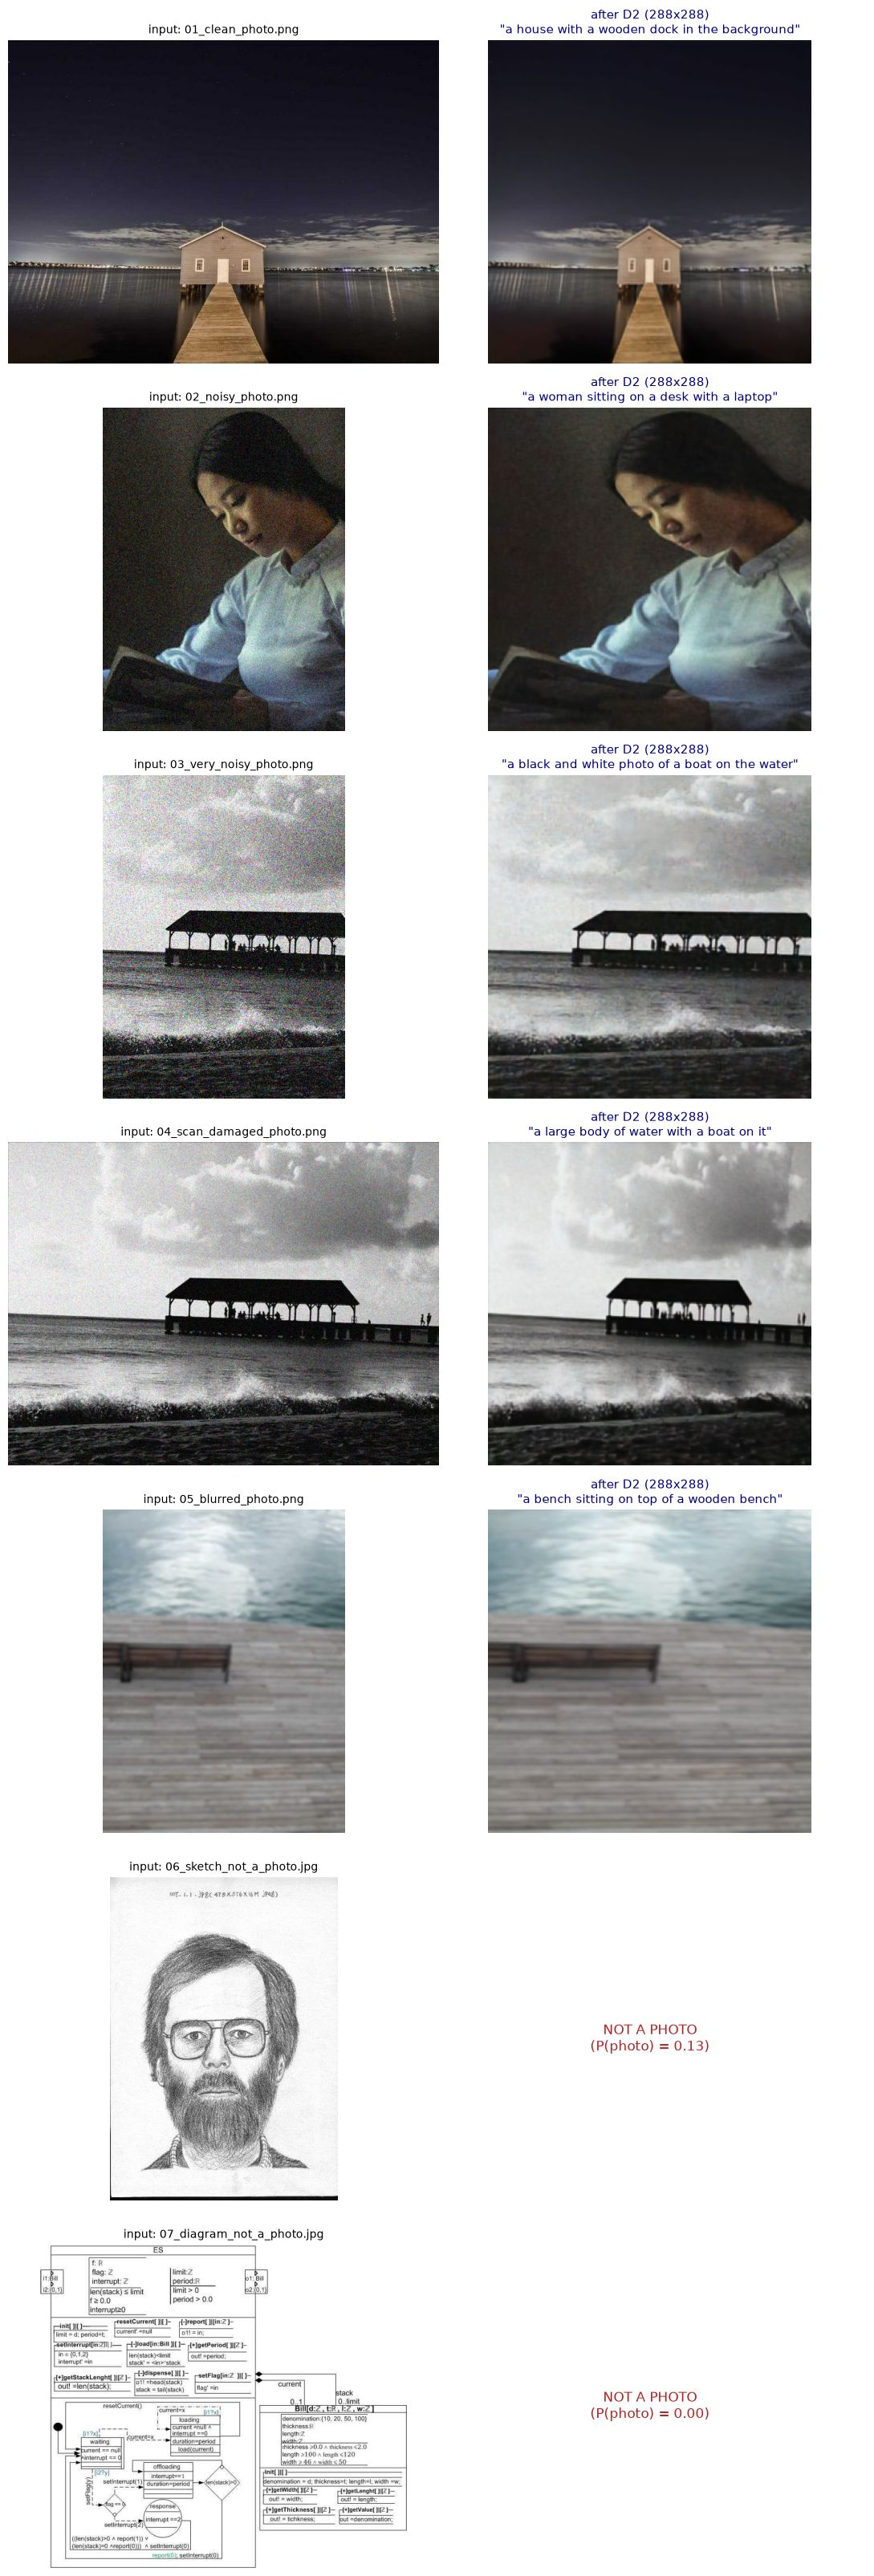

In [5]:
demo = run_workflow(from_folder("data/pipeline_demo"))

**Reading.** D1 keeps the five photos, including the very noisy one (P = 0.90) and the blurred one (P = 0.59), and stops the
sketch (0.14) and the diagram (0.00) before D2 and D3: no caption is written for them. With D2, the caption of the very
noisy photo names the boat ("a black and white photo of a boat on the water", against "a body of water" without D2);
on the clean and slightly noisy photos the two captions say the same thing in other words. D2 does not remove blur
(it was trained on noise only), and on the blurred photo the caption after D2 is worse ("a bench ... on top of a wooden
bench"): blur is the limit of this D2, and the reason for the deblurring of `deliverable2_improved.ipynb`. About 5.5 s
per photo, most of it ConvNeXt-Large on the CPU.

### 13.2 Images given by link, or your own images

- **By link**: any public image address (needs internet).
- **Your own images**: drop them in the folder `my_photos/` (next to this notebook), or paste file paths or links in
  `MY_IMAGES`, then run the cell.
- **Upload**: in an interactive session, the upload button below, then the cell after it.

,image,size,P(photo) D1,D1,caption without D2,caption after D2 (final),seconds
0,480,640x480,0.662000,photo,a tree with leaves on it sitting in the leaves,a tree with leaves on it sitting in the leaves,5.700000
1,480,640x480,0.614000,photo,a man laying on a surfboard in the water,a man laying on a surfboard in the water,5.400000


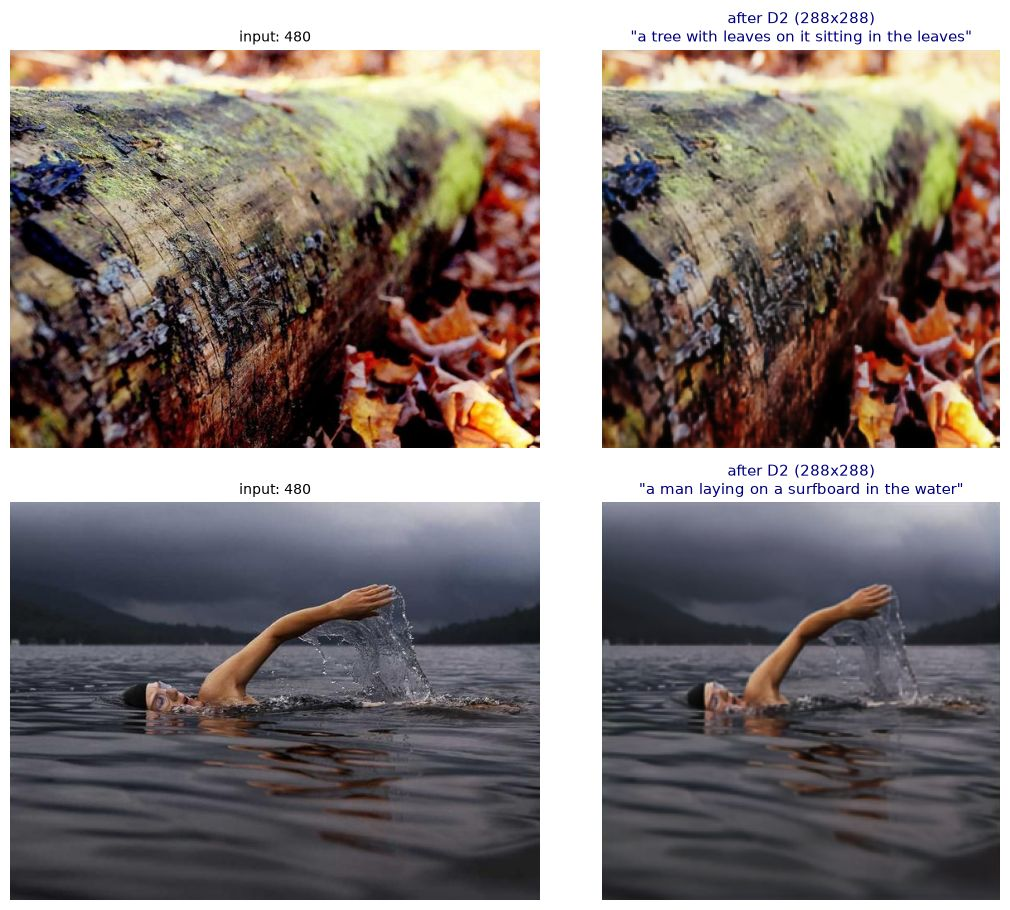

In [6]:
by_link = run_workflow(from_urls(["https://picsum.photos/seed/tounum1/640/480", "https://picsum.photos/seed/tounum2/640/480"]))

In [7]:
MY_FOLDER = "my_photos"   # drop your photos here
MY_IMAGES = [             # or paste paths / links here, e.g. "/home/me/Pictures/holiday.jpg" or "https://.../photo.jpg"
]
Path(MY_FOLDER).mkdir(exist_ok=True)
mine = from_folder(MY_FOLDER) + [(Path(s).name, read_rgb(s)) for s in MY_IMAGES if not s.startswith("http")] \
       + from_urls([s for s in MY_IMAGES if s.startswith("http")])
if mine:
    my_results = run_workflow(mine)
else:
    print(f"No image yet: put photos in '{MY_FOLDER}/' or paste paths / links in MY_IMAGES, then run this cell again.")

No image yet: put photos in 'my_photos/' or paste paths / links in MY_IMAGES, then run this cell again.


In [8]:
import ipywidgets as widgets
from IPython.display import display

uploader = widgets.FileUpload(accept="image/*", multiple=True, description="Upload images")
display(uploader)

FileUpload(value=(), accept='image/*', description='Upload images', multiple=True)

In [9]:
uploaded = [(f["name"], read_rgb(bytes(f["content"]))) for f in uploader.value]
if uploaded:
    run_workflow(uploaded)
else:
    print("No image uploaded yet: use the button above, then run this cell again.")

No image uploaded yet: use the button above, then run this cell again.


## 14. Analysis, limits and recommendations

*Numbers of our run (seed 42).*

### 14.1 What each step brought

On the same 5,000 test photos (4 human captions each), one change at a time:

| Step | BLEU-4 | CIDEr-D | distinct captions | repeated 2-gram |
|---|---|---|---|---|
| Section 7: first model (12,000 images) | 0.180 | 0.642 | 2,896 | 23.0 % |
| 11.1: all of COCO (InceptionV3) | 0.216 | 0.802 | 3,108 | 12.7 % |
| 11.2: EfficientNetV2-S | 0.229 | 0.850 | 3,356 | 11.3 % |
| 11.2: ConvNeXt-Large | 0.253 | 0.980 | 3,881 | 12.5 % |
| 11.2: ConvNeXt-Large, training continued | 0.264 | 1.009 | 3,840 | 15.1 % |
| 11.3: greedy (as before) | 0.264 | 1.009 | 3,840 | 15.1 % |
| 11.3: beam 3, no repeated 2-gram | 0.289 | 1.061 | 3,398 | 0.0 % |
| 11.4: SCST, greedy | 0.296 | 1.116 | 3,227 | 12.0 % |
| 11.4: SCST, beam 3, no repeated 2-gram | 0.301 | 1.140 | 2,933 | 0.0 % |
| Human (one caption vs the 4 others) | 0.190 | 0.883 | 4,965 | 3.4 % |

Four lessons, in the order they appeared:

1. **Data first.** The first model overfitted after 4 epochs on 12,000 images. With all of COCO (7 times more images)
   the overfitting disappears. A bigger network on 12,000 images would only have overfitted faster.
2. **The image representation is the strongest lever.** With the same decoder, each better pre-trained CNN gives
   better captions (InceptionV3 -> EfficientNetV2-S -> ConvNeXt-Large). The decoder can only describe what the CNN
   "sees" in the 81 regions.
3. **Searching better is free.** Beam search without repeated pairs of words improves the captions of the same
   network, with no training, and removes every repetition.
4. **Train on what is measured, carefully.** SCST optimises the score of whole sentences. Its first try destroyed the
   model: a reinforcement-learning loss with a badly chosen baseline pushes everything down. With a baseline made of
   the other samples of the same image, a 5x smaller learning rate and early stopping on validation, it improves the
   model (section 11.4).

From the first model to the final one: BLEU-4 0.180 -> 0.301 and CIDEr-D 0.642 -> 1.140 (SCST
with beam 3, no repeated 2-gram) on these 5,000 photos.

### 14.2 How good are the captions?

- **On the whole test split** (18,493 photos, section 12.6) the final model (SCST, beam 3, no repeated 2-gram) gets BLEU-1 0.729,
  BLEU-4 0.301 and CIDEr-D 1.124. A human caption scored the same way gets BLEU-4 0.195 and CIDEr-D 0.873.
- **This does not mean the model writes better than a person.** The scores count the words shared with the 4 other
  human captions: the model learned to write the most expected sentence, while people write more specific, more
  varied ones (18,221 different captions for 18,493 photos, against 8,217 for the model; 10.5 words on
  average against 9.0). A specific and correct detail is penalised if the 4 others did not mention it.
- **Per photo** (histogram of 12.6), the score varies a lot: the best captions are those of frequent scenes
  (trains, giraffes, pizzas, tennis), the worst ones of unusual scenes, small or rare objects, and text inside the
  image (section 12.6).
- **Published reference points** (order of magnitude only: other splits, 5 references instead of 4): *Show, Attend
  and Tell* (Xu et al., 2015, CNN + LSTM with attention) about 0.24 BLEU-4; with SCST (Rennie et al., 2017) about
  0.33 BLEU-4 and 1.14 CIDEr-D; recent vision-language models pre-trained on hundreds of millions of image-text pairs
  (for example BLIP, 2022) 1.3 to 1.4 CIDEr-D. Our CNN + RNN is in the range of the CNN + RNN models trained with SCST.

### 14.3 Bias and variance

- **First model: variance.** Training loss down, validation loss up from epoch 5: too few images for the network.
  Fixed by the data (section 11.1).
- **Final model: bias.** Training and validation losses stay close (2.01 and 2.17 at the kept epoch): the model does
  not overfit any more, its limit is its capacity and what it is given: a frozen encoder never adapted to captions,
  a GRU of 512 units with one attention head, a vocabulary of 5,000 words.

### 14.4 Limits

- **Domain.** COCO contains modern colour photos of everyday scenes. TouNum's archives are scans, often old, often
  black and white. The captions have not been measured on such images (there are no human captions for them); the
  encoder was pre-trained on colour images.
- **Vocabulary.** 5,000 everyday words: no names of people, places or dates, which is what an archive would want.
  Words outside the vocabulary can never be written.
- **Metrics.** BLEU and CIDEr-D count shared word sequences with 4 human captions: synonyms are penalised, and SCST
  optimises CIDEr-D, so it can learn phrasings that the score likes more than people do. No human evaluation was
  done.
- **Frozen encoder.** ConvNeXt-Large is never fine-tuned (2 GB GPU): the image representation is the one of
  ImageNet classification.
- **Workflow.** D1 and D2 are the models of deliverables 1 and 2 as delivered, at 128x128: D1 rejects strongly
  noisy photos (it was trained on clean images), and D2, trained on photos reduced to 128x128 and applied here at
  288x288, does not remove blur. ConvNeXt-Large runs on the CPU (a few seconds per photo). The effect of D2 on the
  captions is shown on the demo images only, not measured on a large set. Improved versions of D1 and D2 (photo
  categories, robustness to damaged photos, restoration at full resolution with deblurring) are in
  `deliverable1_improved.ipynb`, `deliverable2_improved.ipynb` and `deliverable3_improved.ipynb`.
- **One run** (seed 42); GPU computations are not exactly reproducible, the third decimal of the scores is not
  meaningful. **Images squashed** to 288x288 (no crop).

### 14.5 Recommendations for TouNum

1. **Measure on their archives first.** 200 archive photos with captions written by archivists give the real score
   on the client's data, and can be used to fine-tune the decoder on their domain.
2. **A larger GPU** (16 GB or more): fine-tune the last stages of the encoder together with the decoder, and run the
   encoder on the GPU in the workflow (about 75 photos per second already on our 2 GB card, 4 at a time).
3. **Vision-language models** (BLIP and its successors, pre-trained on hundreds of millions of image-text pairs) are
   the state of the art (CIDEr-D 1.3 to 1.4 on COCO). They were excluded by the rules of this project (a CNN and an
   RNN trained by us), but they are the natural next step for a production system.
4. **Use the improved D1 and D2** (`*_improved.ipynb`): D1 also sorts the rejected images by category and accepts
   damaged photos after a repair by D2; D2 restores photos at their original size, including heavy blur.
5. **A human in the loop.** The captions are suggestions to validate; the archivists could review first the photos
   whose caption is the least likely for the model (a confidence score, still to be measured).
6. **Search by content.** Even an imperfect sentence names the main objects and the scene: the words of the captions
   can index the archive, so that a user can search "train station" or "boat" in thousands of digitised photos.

## 15. Evaluation dataset (last cell)

**Change only `INPUT_FOLDER`** to the folder of the dataset given for the demonstration, then run the cell (after the
first code cell and the cell of section 11.3 that defines `decode`, see section 13). Every image goes through D1, D2
and D3, and the full table is saved to `reports/d3_workflow_results.csv`.

,image,size,P(photo) D1,D1,caption without D2,caption after D2 (final),seconds
0,01_clean_photo.png,640x480,0.992000,photo,a white house sitting on top of a wooden pier,a house with a wooden dock in the background,5.800000
1,02_noisy_photo.png,480x640,0.986000,photo,a woman sitting at a table with a laptop,a woman sitting on a desk with a laptop,5.500000
2,03_very_noisy_photo.png,480x640,0.897000,photo,a black and white photo of a body of water,a black and white photo of a boat on the water,5.800000
3,04_scan_damaged_photo.png,1024x768,0.998000,photo,a black and white photo of a boat on the water,a large body of water with a boat on it,5.400000
4,05_blurred_photo.png,480x640,0.589000,photo,a bench sitting on top of a wooden pier,a bench sitting on top of a wooden bench,5.400000
5,06_sketch_not_a_photo.jpg,411x583,0.135000,not a photo: stop,-,-,0.100000
6,07_diagram_not_a_photo.jpg,787x695,0.001000,not a photo: stop,-,-,0.100000


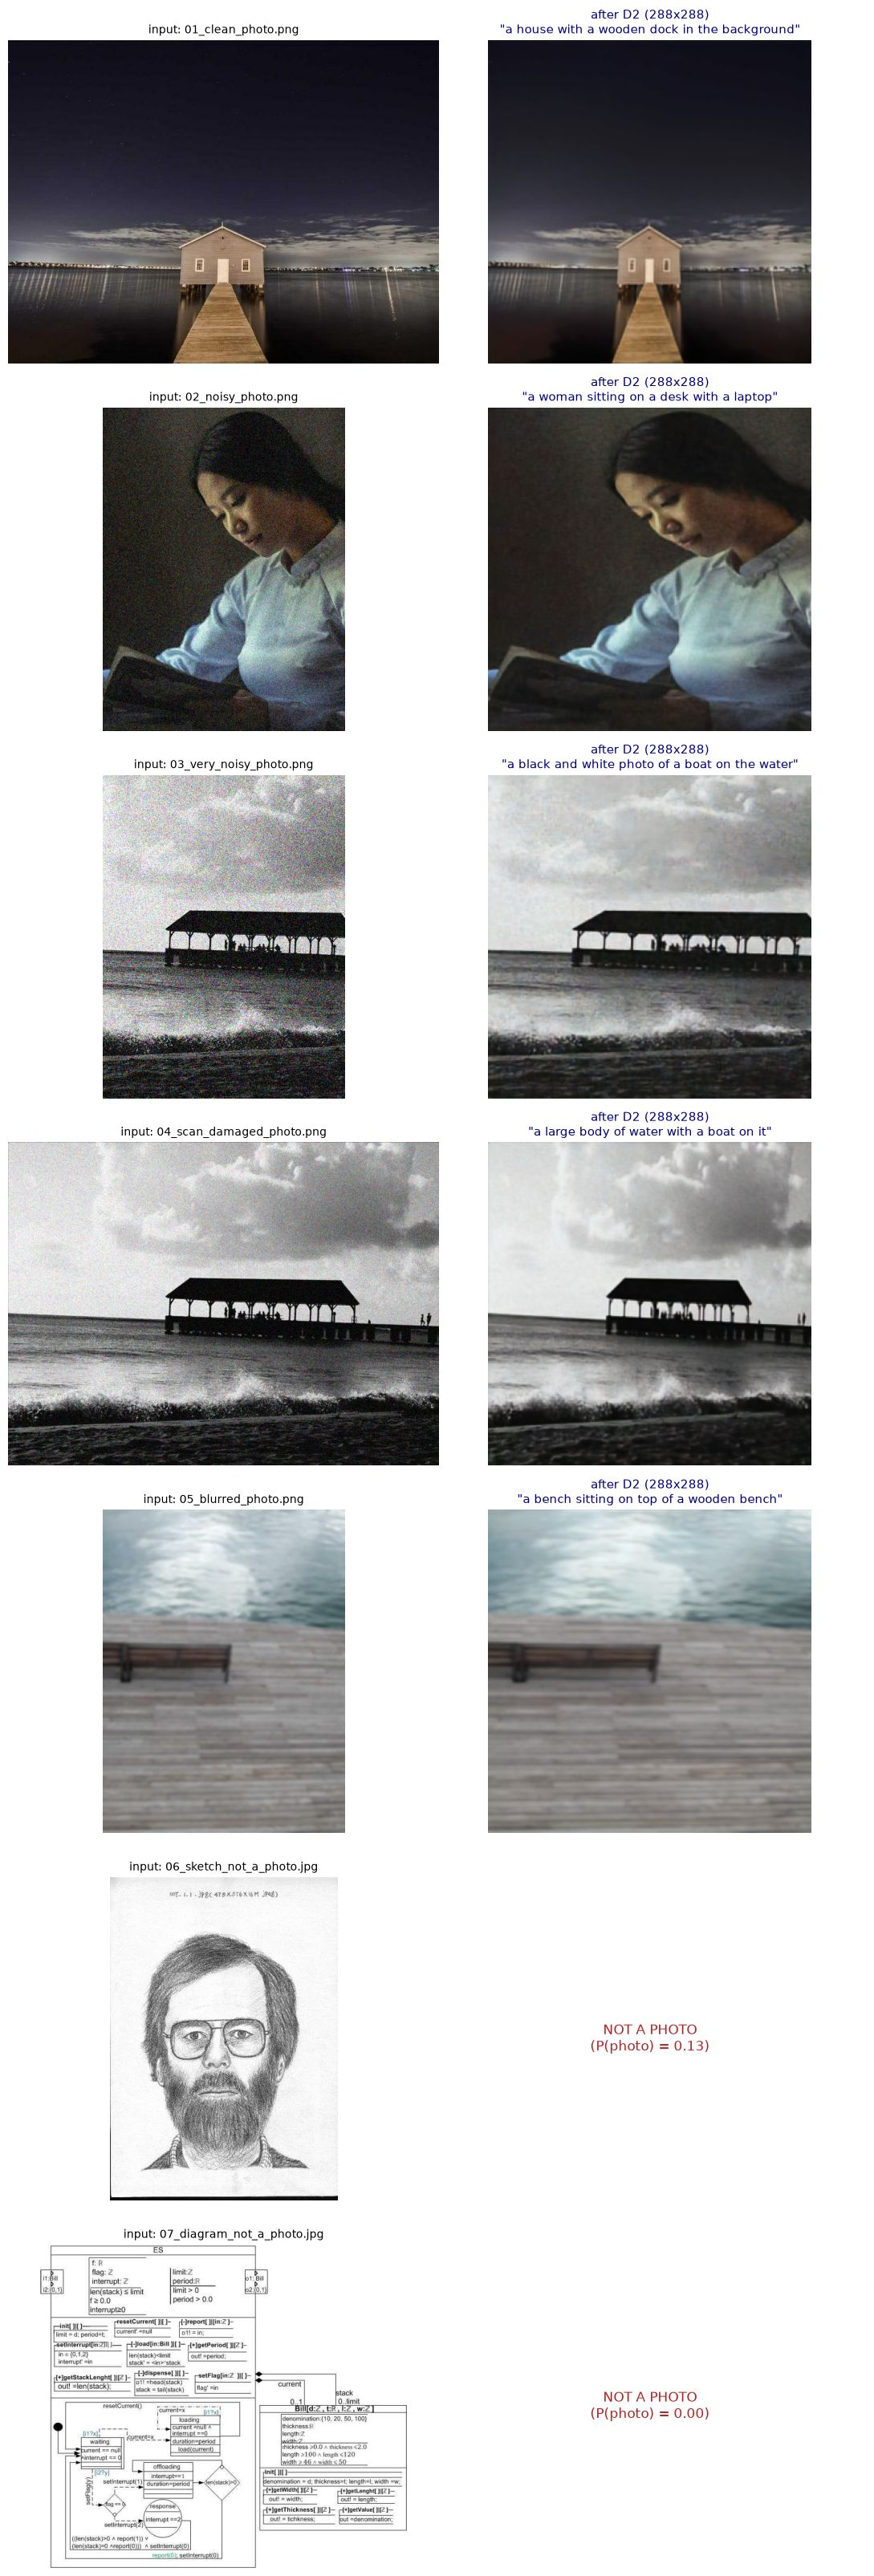

7 images | photos: 5 | not photos: 2 | total 28 s


In [10]:
INPUT_FOLDER = "data/pipeline_demo"   # <- the folder of the evaluation dataset
results = run_workflow(from_folder(INPUT_FOLDER))
results.to_csv("reports/d3_workflow_results.csv", index=False)
print(f"{len(results)} images | photos: {(results['D1'] == 'photo').sum()} | not photos: {(results['D1'] != 'photo').sum()} "
      f"| total {results['seconds'].sum():.0f} s")